# Frozen TIB RQ2/RQ4 120-record evaluation

The 120 creator `valid` records were selected before generation, 40 per pinned source-token length stratum. S1 and S3 summarize the same full transcript with the same Qwen checkpoint. Primary result: ROUGE-L agreement with creator abstracts and measured pipeline cost. These abstracts were already inspected in EDA; results cannot establish factual video quality or multimodal benefit. Grouped intervals are exploratory sensitivity, not population-superiority tests.

Upload the supplied `data` folder to `MyDrive/RQ2_TIB_120_20261012/data`, select a Tesla T4 GPU and run cells in order. Use a fresh run directory for any changed cohort, code, configuration or hardware. Checkpoints can be resumed only with matching identity. Keep the Colab tab/runtime active; Drive checkpoints survive disconnection but an in-flight model call may stop.


In [2]:
# Validate supplied identity and all 120 source/reference hashes before pip or model loading.
import gzip, hashlib, json, pathlib, time
from google.colab import drive
drive.mount('/content/drive')
ROOT = pathlib.Path('/content/drive/MyDrive/RQ2_TIB_120_20261012')
DATA = ROOT/'data'; RUN = ROOT/'formal-run-v1'
MANIFEST = json.loads((DATA/'tib-rq2-rq4-120-cohort-261012.json').read_text(encoding='utf8'))
PROTOCOL = json.loads((DATA/'tib-rq2-rq4-120-protocol-261012.json').read_text(encoding='utf8'))
def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, ensure_ascii=False,
        separators=(',', ':'), allow_nan=False).encode()).hexdigest()
assert digest({k:v for k,v in MANIFEST.items() if k!='manifest_sha256'}) == MANIFEST['manifest_sha256']
assert digest({k:v for k,v in PROTOCOL.items() if k!='protocol_sha256'}) == PROTOCOL['protocol_sha256']
assert PROTOCOL['cohort_manifest_sha256']==MANIFEST['manifest_sha256']
assert PROTOCOL['selected_count']==120 and len(MANIFEST['selected'])==120
bundle_file = DATA/'tib-evaluation-120.jsonl.gz'
items=[]; payload=hashlib.sha256(); complete=False; metadata=None
with gzip.open(bundle_file,'rt',encoding='utf8',newline='') as stream:
    for line in stream:
        record=json.loads(line)
        if record.get('kind')=='checksum':
            assert record['sha256']==payload.hexdigest(); complete=True; continue
        assert not complete
        payload.update(line.encode('utf8'))
        if record['kind']=='metadata': metadata=record['value']
        elif record['kind']=='item': items.append(record['value'])
        else: raise ValueError('Unexpected bundle record')
assert complete and len(items)==120
assert payload.hexdigest()==MANIFEST['bundle']['payload_sha256']
by_id={f"{r['split']}/{r['source_index']}":r for r in items}
assert len(by_id)==120 and set(by_id)=={r['id'] for r in MANIFEST['selected']}
for entry in MANIFEST['selected']:
    item=by_id[entry['id']]
    for text_field, hash_field in [('source_text','source_sha256'),('reference_text','reference_sha256')]:
        assert hashlib.sha256(item[text_field].encode('utf8')).hexdigest()==entry[hash_field]==item[hash_field]
assert metadata['selection_sha256']==MANIFEST['selection_sha256']
print('Frozen inputs verified:', len(items), 'records; cohort', MANIFEST['manifest_sha256'])
SESSION_START=time.monotonic()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Frozen inputs verified: 120 records; cohort ed52d8a41a89ffbdc033b8ec88c04eaf17c4b36393dc8c6d3701415c4b92e918


In [3]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
    'transformers>=4.45,<5', 'datasets', 'huggingface_hub',
    'sentence-transformers', 'bert-score', 'sentencepiece', 'pandas'])


0

In [4]:
# Embedded source is fixed by the protocol; no remote code checkout.
SOURCES = {'rq2_tib_benchmark': '"""TIB benchmark entry point: prepare data automatically, then run paired S1/S3."""\r\n\r\nimport hashlib\r\nimport json\r\nimport os\r\nimport tempfile\r\nimport time\r\nfrom dataclasses import asdict, dataclass\r\nfrom pathlib import Path\r\n\r\nfrom experiments.scripts import rq2_tib_benchmark_dataset as data\r\nfrom experiments.scripts import rq2_tib_benchmark_bundle as bundles\r\nfrom experiments.scripts.rq2_tib_benchmark_pair import run_source_pair\r\n\r\n\r\ndef load_or_prepare_data(path, *, rebuild=False, rows_by_split=None, verify_counts=True):\r\n    """Shared by the benchmark and preparation notebook; no prior prep run needed."""\r\n    path = Path(path)\r\n    if path.exists() and not rebuild:\r\n        return bundles.load_benchmark_bundle(path)\r\n    rows = rows_by_split if rows_by_split is not None else data.load_pinned_splits(data.SPLITS)\r\n    prepared = data.prepare_dataset(rows, verify_counts=verify_counts)\r\n    bundle = bundles.build_benchmark_bundle(prepared)\r\n    bundles.save_benchmark_bundle(bundle, path, overwrite=rebuild)\r\n    return bundle\r\n\r\n\r\n@dataclass(frozen=True)\r\nclass BenchmarkConfig:\r\n    chunk_tokens: int = 512\r\n    map_output_tokens: int = 96\r\n    final_output_tokens: int = 384\r\n    seed: int = 42\r\n    temperature: float = 0.0\r\n    bootstrap_samples: int = 5000\r\n    bootstrap_seed: int = 20261009\r\n\r\n    def validate(self):\r\n        budgets = (self.chunk_tokens, self.map_output_tokens, self.final_output_tokens, self.bootstrap_samples)\r\n        if any(not isinstance(value, int) or isinstance(value, bool) or value <= 0 for value in budgets):\r\n            raise ValueError("Token budgets must be positive")\r\n        if self.temperature != 0:\r\n            raise ValueError("This runner uses deterministic greedy decoding")\r\n\r\n\r\ndef _hash(value):\r\n    return hashlib.sha256(json.dumps(value, ensure_ascii=False, sort_keys=True,\r\n                                    separators=(",", ":"), allow_nan=False).encode()).hexdigest()\r\n\r\n\r\ndef _save_result(value, path):\r\n    fd, temporary = tempfile.mkstemp(prefix=path.name, suffix=".tmp", dir=path.parent)\r\n    try:\r\n        with os.fdopen(fd, "w", encoding="utf-8") as stream:\r\n            json.dump(value, stream, ensure_ascii=False, indent=1, allow_nan=False)\r\n        for attempt in range(5):\r\n            try:\r\n                os.replace(temporary, path)\r\n                break\r\n            except PermissionError as exc:\r\n                # Windows indexers can briefly lock a just-replaced checkpoint.\r\n                # Preserve atomic replacement and still surface persistent errors.\r\n                if os.name != "nt" or getattr(exc, "winerror", None) not in {5, 32, 33} or attempt == 4:\r\n                    raise\r\n                time.sleep(.05 * (attempt + 1))\r\n    finally:\r\n        if os.path.exists(temporary):\r\n            os.unlink(temporary)\r\n\r\n\r\n\r\ndef run_benchmark(backend, *, data_path, output_dir, config=None, rebuild_data=False,\r\n                  rows_by_split=None, verify_counts=True, progress=None, semantic_scorer="auto",\r\n                  phase="all", summarize=True, on_event=None):\r\n    """Single benchmark call includes acquisition, processing, generation and scoring.\r\n\r\n    Existing completed predictions resume by full run/item identity. Failed\r\n    items remain in the denominator and are retried on the next invocation.\r\n    """\r\n    from experiments.scripts.rq2_tib_benchmark_results import (\r\n        SCORER, score_pair, summarize_results, validate_semantic_scores,\r\n    )\r\n\r\n    if phase not in {"all", "generate", "evaluate"}:\r\n        raise ValueError("phase must be all, generate or evaluate")\r\n    config = config or BenchmarkConfig()\r\n    config.validate()\r\n    def emit(**event):\r\n        if on_event:\r\n            on_event(event)\r\n    emit(stage="data", status="started")\r\n    if phase == "generate":\r\n        semantic_scorer = None\r\n    elif semantic_scorer == "auto":\r\n        from experiments.scripts.rq2_tib_benchmark_metrics import SemanticScorer\r\n        semantic_scorer = SemanticScorer()\r\n    bundle = load_or_prepare_data(data_path, rebuild=rebuild_data,\r\n                                 rows_by_split=rows_by_split, verify_counts=verify_counts)\r\n    emit(stage="data", status="completed", total=len(bundle["items"]))\r\n    output_dir = Path(output_dir)\r\n    output_dir.mkdir(parents=True, exist_ok=True)\r\n    # Retain legacy default cache identity, but aggregation-only settings must\r\n    # never invalidate generation. These historical placeholders are not used\r\n    # for bootstrap computation; summarize_results gets the requested settings.\r\n    generation_config = {**asdict(config), "bootstrap_samples": 5000, "bootstrap_seed": 20261009}\r\n    run_identity = _hash({"selection": bundle["metadata"]["selection_sha256"],\r\n                          "config": generation_config, "model": backend.model_id,\r\n                          "tokenizer": backend.tokenizer_id, "runner_version": 1, "scorer": SCORER})\r\n    results = []\r\n    for index, item in enumerate(bundle["items"], 1):\r\n        source = bundles.generation_input(item)\r\n        identity = _hash({"run": run_identity, "id": source["id"],\r\n                          "source": item["source_sha256"], "reference": item["reference_sha256"],\r\n                          "timed_segments": _hash(source["transcript_segments"])})\r\n        path = output_dir / f"{item[\'split\']}-{item[\'source_index\']}.json"\r\n        def item_event(event):\r\n            emit(**{**event, "index":index, "total":len(bundle["items"]), "id":source["id"]})\r\n        old = json.loads(path.read_text(encoding="utf-8")) if path.exists() else None\r\n        if phase == "evaluate" and old is None:\r\n            raise FileNotFoundError(f"Generation checkpoint missing; run generation cell first: {path}")\r\n        if old is not None:\r\n            checksum = old.get("result_sha256")\r\n            if old.get("identity_sha256") != identity or checksum != _hash({k:v for k,v in old.items() if k != "result_sha256"}):\r\n                raise ValueError(f"Existing prediction identity/content differs: {path}")\r\n        if old is not None and old.get("status") == "completed":\r\n            result = old\r\n            item_event({"stage":"generation", "status":"reused"})\r\n        elif phase == "evaluate":\r\n            result = old\r\n            item_event({"stage":"evaluation", "status":"skipped", "reason":old["status"]})\r\n        else:\r\n            result = {"id": source["id"], "split": item["split"], "source_index": item["source_index"],\r\n                      "doi": item["doi"], "genre": item["genre"], "subject": item["subject"],\r\n                      "duration_minutes": item["duration_minutes"], "identity_sha256": identity,\r\n                      "run_sha256": run_identity, "source_sha256": item["source_sha256"],\r\n                      "reference_sha256": item["reference_sha256"], "config": asdict(config)}\r\n            if old is not None:\r\n                result["prior_attempts"] = old.get("prior_attempts", []) + [{\r\n                    "arms": old.get("arms", {}), "seconds": old.get("seconds", 0),\r\n                    "error": old.get("error", ""), "status": old["status"],\r\n                    "shared_preparation_seconds": old.get("shared_preparation_seconds")}]\r\n            started = time.perf_counter()\r\n            def checkpoint(partial):\r\n                result.update(partial, status="in_progress", seconds=time.perf_counter() - started)\r\n                _save_result({**result, "result_sha256": _hash(result)}, path)\r\n            try:\r\n                result.update(run_source_pair(source, backend, config,\r\n                    completed_arms=old.get("arms", {}) if old else None, on_progress=checkpoint, on_event=item_event))\r\n                item_event({"stage":"rouge_l", "status":"started"})\r\n                result["scores"] = score_pair(result["arms"], bundles.evaluation_target(item)["reference_text"])\r\n                result["status"] = "completed"\r\n                item_event({"stage":"rouge_l", "status":"completed", "scores":result["scores"]})\r\n            except (ValueError, RuntimeError, OSError) as exc:\r\n                result.update(getattr(exc, "partial_pair", {}))\r\n                item_event({"stage":"generation", "status":"failed", "error":str(exc)})\r\n                result.update(status="failed", error_type=getattr(exc, "original_error_type", type(exc).__name__), error=str(exc))\r\n            result["seconds"] = time.perf_counter() - started\r\n            result["result_sha256"] = _hash(result)\r\n            _save_result(result, path)\r\n        # Evaluation has a separate identity so adding/changing scorers never\r\n        # invalidates saved generation. A failed score is retried, not regenerated.\r\n        if phase != "generate" and result["status"] == "completed" and semantic_scorer is not None:\r\n            evaluation = {"scorer": semantic_scorer.metadata,\r\n                          "prediction": _hash({name: arm["summary"] for name, arm in result["arms"].items()}),\r\n                          "source": item["source_sha256"], "reference": item["reference_sha256"]}\r\n            evaluation_identity = _hash(evaluation)\r\n            if result.get("evaluation_sha256") != evaluation_identity or result.get("evaluation_status") != "completed":\r\n                evaluation_history = list(result.get("evaluation_attempts", []))\r\n                if not evaluation_history and result.get("evaluation_status"):\r\n                    evaluation_history.append({"identity": result.get("evaluation_sha256"),\r\n                        "configuration": result.get("evaluation_config"), "status": result["evaluation_status"],\r\n                        "seconds": result.get("evaluation_seconds", 0), "error": result.get("evaluation_error")})\r\n                item_event({"stage":"evaluation", "status":"started"})\r\n                score_started = time.perf_counter()\r\n                result.pop("semantic_scores", None)\r\n                result.pop("evaluation_error", None)\r\n                original_callback = getattr(semantic_scorer, "on_event", None)\r\n                if on_event is not None and hasattr(semantic_scorer, "on_event"):\r\n                    semantic_scorer.on_event = item_event\r\n                try:\r\n                    result["semantic_scores"] = validate_semantic_scores(semantic_scorer.score_pair(\r\n                        result["arms"], bundles.evaluation_target(item)["reference_text"], source["transcript"]))\r\n                    result["evaluation_status"] = "completed"\r\n                except (ValueError, RuntimeError, OSError, ImportError) as exc:\r\n                    result.update(evaluation_status="failed", evaluation_error=f"{type(exc).__name__}: {exc}")\r\n                finally:\r\n                    if on_event is not None and hasattr(semantic_scorer, "on_event"):\r\n                        semantic_scorer.on_event = original_callback\r\n                item_event({"stage":"evaluation", "status":result["evaluation_status"], "error":result.get("evaluation_error")})\r\n                result.update(evaluation_sha256=evaluation_identity, evaluation_config=evaluation["scorer"],\r\n                              evaluation_seconds=time.perf_counter() - score_started)\r\n                result["evaluation_attempts"] = evaluation_history + [{"identity": evaluation_identity,\r\n                    "configuration": evaluation["scorer"], "status": result["evaluation_status"],\r\n                    "seconds": result["evaluation_seconds"], "error": result.get("evaluation_error")}]\r\n                result.pop("result_sha256", None)\r\n                result["result_sha256"] = _hash(result)\r\n                _save_result(result, path)\r\n            else:\r\n                item_event({"stage":"evaluation", "status":"reused"})\r\n        results.append(result)\r\n        if progress:\r\n            progress(index, len(bundle["items"]), result)\r\n    benchmark = {"metadata": bundle["metadata"], "results": results, "summary": None,\r\n                 "run_sha256": run_identity,\r\n                 "evaluation_configuration": semantic_scorer.metadata if semantic_scorer is not None else None}\r\n    if summarize:\r\n        emit(stage="aggregation", status="started")\r\n        summarize_benchmark(benchmark, output_dir=output_dir, config=config)\r\n        emit(stage="aggregation", status="completed")\r\n    return benchmark\r\n\r\n\r\ndef summarize_benchmark(benchmark, *, output_dir, config=None):\r\n    """Aggregate already saved generation/evaluation; never loads an encoder."""\r\n    from experiments.scripts.rq2_tib_benchmark_results import summarize_results\r\n    config = config or BenchmarkConfig()\r\n    config.validate()\r\n    results, metadata = benchmark["results"], benchmark["metadata"]\r\n    summary = summarize_results(results, bootstrap_samples=config.bootstrap_samples, seed=config.bootstrap_seed)\r\n    summary.update(run_sha256=benchmark["run_sha256"], selected_count=len(results),\r\n                   selection_sha256=metadata["selection_sha256"])\r\n    summary["evaluation"] = {"configuration": benchmark.get("evaluation_configuration"),\r\n                             "completed": sum(row.get("evaluation_status") == "completed" for row in results),\r\n                             "failed": sum(row.get("evaluation_status") == "failed" for row in results),\r\n                             "seconds": sum(sum(attempt["seconds"] for attempt in row["evaluation_attempts"])\r\n                                            if row.get("evaluation_attempts") else row.get("evaluation_seconds", 0)\r\n                                            for row in results)}\r\n    _save_result(summary, Path(output_dir) / "summary.json")\r\n    benchmark["summary"] = summary\r\n    return benchmark\r\n', 'rq2_tib_benchmark_dataset': '"""Prepare pinned TIB text inputs for a limited RQ2 abstract-agreement benchmark.\n\nThis module returns data and audit tables in memory. It never qualifies creator\nabstracts as factual ground truth or silently truncates a transcript.\n"""\n\nfrom __future__ import annotations\n\nimport hashlib\nimport json\nimport math\nimport re\nfrom collections import Counter, defaultdict\nfrom typing import Iterable, Mapping\n\nDATASET = "gigant/tib"\nREVISION = "e6ab9fd7c6acd164f3284b8c4b17eb9d94681eee"\nSPLITS = ("train", "valid", "test")\nEXPECTED_COUNTS = {"train": 7282, "valid": 910, "test": 911}\n_RAW_FIELDS = {"source_text", "reference_text", "segment_texts", "segment_starts_seconds",\n               "segment_ends_seconds"}\n\n\ndef _text(value: object) -> str:\n    return str(value or "").strip()\n\n\ndef _normalized(value: object) -> str:\n    return " ".join(_text(value).casefold().split())\n\n\ndef _tokens(value: object) -> list[str]:\n    return re.findall(r"\\b\\w+\\b", _text(value).casefold())\n\n\ndef _digest(value: object) -> str:\n    payload = json.dumps(value, ensure_ascii=False, separators=(",", ":"))\n    return hashlib.sha256(payload.encode("utf-8")).hexdigest()\n\n\ndef prepare_record(split: str, source_index: int, record: Mapping) -> dict:\n    """Keep original segment content and explain every mechanical exclusion."""\n    if split not in SPLITS or not isinstance(source_index, int) or source_index < 0:\n        raise ValueError("A valid creator split and nonnegative source_index are required")\n    transcript = _text(record.get("transcript"))\n    abstract = _text(record.get("abstract"))\n    segments = record.get("transcript_segments")\n    segments = segments if isinstance(segments, Mapping) else {}\n    arrays = [segments.get(field) for field in ("text", "start", "end")]\n    aligned_arrays = all(isinstance(value, (list, tuple)) for value in arrays)\n    texts, starts, ends = (tuple(value) for value in arrays) if aligned_arrays else ((), (), ())\n    clean_texts = tuple(_text(value) for value in texts)\n    source_text = " ".join(clean_texts)\n    structural_reasons: list[str] = []\n    if not transcript:\n        structural_reasons.append("missing_transcript")\n    if len(texts) < 2:\n        structural_reasons.append("insufficient_segments")\n    if not aligned_arrays or len(texts) != len(starts) or len(texts) != len(ends):\n        structural_reasons.append("misaligned_segments")\n    if any(not text for text in clean_texts):\n        structural_reasons.append("empty_segment_text")\n    valid_times = (\n        aligned_arrays\n        and len(texts) == len(starts) == len(ends)\n        and all(\n            isinstance(start, (int, float)) and not isinstance(start, bool)\n            and isinstance(end, (int, float)) and not isinstance(end, bool)\n            and math.isfinite(start) and math.isfinite(end)\n            and 0 <= start <= end\n            for start, end in zip(starts, ends)\n        )\n    )\n    if not valid_times:\n        structural_reasons.append("invalid_segment_times")\n    elif any(starts[i] < starts[i - 1] for i in range(1, len(starts))):\n        structural_reasons.append("unordered_segments")\n    # Overlaps and text disagreement need review, but both arms can use the same\n    # ordered segment text; neither destroys a text-only source by itself.\n    overlap_count = (sum(starts[i] < ends[i - 1] for i in range(1, len(starts)))\n                     if valid_times and "unordered_segments" not in structural_reasons else None)\n    transcript_matches_segments = _tokens(transcript) == _tokens(source_text)\n    reference_reasons = [] if abstract else ["empty_abstract"]\n    flags = []\n    if not _text(record.get("doi")):\n        flags.append("missing_doi")\n    if not _text(record.get("url")):\n        flags.append("missing_source_url")\n    if abstract and len(abstract.split()) < 30:\n        flags.append("short_abstract_under_30_words")\n    if overlap_count:\n        flags.append("overlapping_segments")\n    if transcript and source_text and not transcript_matches_segments:\n        flags.append("transcript_segment_mismatch")\n    license_text = _text(record.get("license"))\n    source_url = _text(record.get("url"))\n    return {\n        "split": split, "source_index": source_index,\n        "doi": _text(record.get("doi")), "title": _text(record.get("title")),\n        "author": _text(record.get("author")), "genre": _text(record.get("genre")),\n        "subject": _text(record.get("subject")), "language": _text(record.get("language")),\n        "release_year": _text(record.get("release_year")),\n        "license_label": license_text.splitlines()[0] if license_text else "",\n        "source_url": source_url, "source_url_present": bool(source_url),\n        "video_url_present": bool(_text(record.get("video_url"))),\n        "transcript_words": len(transcript.split()),\n        "source_words": len(source_text.split()),\n        "abstract_words": len(abstract.split()), "segment_count": len(texts),\n        "duration_minutes": max(ends) / 60 if valid_times and ends else None,\n        "segment_overlap_count": overlap_count,\n        "transcript_matches_segments": transcript_matches_segments,\n        "source_text": source_text, "reference_text": abstract,\n        "segment_texts": clean_texts,\n        "segment_starts_seconds": tuple(float(x) for x in starts) if valid_times else (),\n        "segment_ends_seconds": tuple(float(x) for x in ends) if valid_times else (),\n        "source_sha256": hashlib.sha256(source_text.encode("utf-8")).hexdigest(),\n        "reference_sha256": hashlib.sha256(abstract.encode("utf-8")).hexdigest(),\n        "structural_reasons": structural_reasons,\n        "reference_reasons": reference_reasons,\n        "audit_flags": flags,\n        "text_usable": not structural_reasons,\n        "abstract_agreement_candidate": not structural_reasons and not reference_reasons,\n        "unique_reference_candidate": not structural_reasons and not reference_reasons,\n        "domain_status": "unverified",\n        "reference_status": "unverified_creator_abstract",\n    }\n\n\ndef load_pinned_splits(splits: Iterable[str]) -> dict[str, Iterable[Mapping]]:\n    """Stream explicitly requested creator splits; importing this module stays offline."""\n    requested = tuple(splits)\n    if not requested or len(set(requested)) != len(requested) or set(requested) - set(SPLITS):\n        raise ValueError("Specify distinct train/valid/test splits")\n    from datasets import load_dataset\n\n    return {\n        split: load_dataset(DATASET, split=split, revision=REVISION, streaming=True)\n        for split in requested\n    }\n\n\ndef prepare_dataset(rows_by_split: Mapping[str, Iterable[Mapping]], *,\n                    verify_counts: bool = True) -> dict:\n    """Build a deterministic audit and mechanical candidates without file output."""\n    if not rows_by_split or set(rows_by_split) - set(SPLITS):\n        raise ValueError("Unknown or empty creator split selection")\n    records = [\n        prepare_record(split, index, record)\n        for split in SPLITS if split in rows_by_split\n        for index, record in enumerate(rows_by_split[split])\n    ]\n    counts = {split: sum(row["split"] == split for row in records)\n              for split in SPLITS if split in rows_by_split}\n    if verify_counts and any(count != EXPECTED_COUNTS[split] for split, count in counts.items()):\n        raise ValueError(f"Pinned TIB row count changed: {counts}")\n    shared_groups: dict[str, int] = {}\n    for field in ("doi", "title", "author"):\n        groups: dict[str, list[dict]] = defaultdict(list)\n        for row in records:\n            key = _normalized(row[field])\n            if key:\n                groups[key].append(row)\n        shared = [group for group in groups.values()\n                  if len({row["split"] for row in group}) > 1]\n        shared_groups[field] = len(shared)\n        for group in shared:\n            for row in group:\n                row["audit_flags"].append(f"cross_split_{field}_group")\n    references: dict[str, list[dict]] = defaultdict(list)\n    for row in records:\n        key = _normalized(row["reference_text"])\n        if key and row["text_usable"]:\n            references[key].append(row)\n    for group in references.values():\n        if len(group) > 1:\n            # A reused abstract cannot distinguish the content of individual talks.\n            cross_split = len({row["split"] for row in group}) > 1\n            for row in group:\n                row["audit_flags"].append("shared_abstract_group")\n                if cross_split:\n                    row["audit_flags"].append("cross_split_shared_abstract_group")\n                row["unique_reference_candidate"] = False\n    for row in records:\n        row["audit_flags"].sort()\n    candidates = [row for row in records if row["abstract_agreement_candidate"]]\n    broad_pool = [row for row in records if row["unique_reference_candidate"]]\n    broad_identity = [{"split": row["split"], "source_index": row["source_index"],\n                       "doi": row["doi"], "reference_sha256": row["reference_sha256"]}\n                      for row in broad_pool]\n    duration_bins = Counter(\n        "unknown" if row["duration_minutes"] is None else\n        "under_15" if row["duration_minutes"] < 15 else\n        "15_to_30" if row["duration_minutes"] < 30 else\n        "30_to_60" if row["duration_minutes"] < 60 else\n        "60_to_90" if row["duration_minutes"] < 90 else "90_plus"\n        for row in broad_pool\n    )\n    audit = [{key: value for key, value in row.items() if key not in _RAW_FIELDS}\n             for row in records]\n    return {\n        "dataset": DATASET, "revision": REVISION,\n        "splits_read": [split for split in SPLITS if split in rows_by_split],\n        "all_splits_scanned": set(rows_by_split) == set(SPLITS),\n        "test_content_accessed": "test" in rows_by_split,\n        "source_count": len(records), "candidate_count": len(candidates),\n        "broad_pool_count": len(broad_pool),\n        "broad_pool_ids": [(row["split"], row["source_index"]) for row in broad_pool],\n        "broad_pool_sha256": _digest(broad_identity),\n        "broad_pool_diversity": {\n            "genre": dict(Counter(row["genre"] for row in broad_pool)),\n            "subject": dict(Counter(row["subject"] for row in broad_pool)),\n            "release_year": dict(Counter(row["release_year"] for row in broad_pool)),\n            "duration_bin": dict(duration_bins),\n        },\n        "counts_by_split": counts, "shared_group_counts": shared_groups,\n        "structural_exclusions": dict(Counter(reason for row in records\n                                              for reason in row["structural_reasons"])),\n        "reference_exclusions": dict(Counter(reason for row in records\n                                             for reason in row["reference_reasons"])),\n        "audit": audit, "records": records,\n        "status": "mechanical_candidates_only",\n    }\n\n\ndef freeze_abstract_agreement_cohort(prepared: Mapping,\n                                     selected_ids: Iterable[tuple[str, int]]) -> dict:\n    """Freeze explicit candidates for a limited, text-only paired comparison."""\n    if prepared.get("dataset") != DATASET or prepared.get("revision") != REVISION:\n        raise ValueError("Dataset or revision does not match pinned TIB")\n    selected = list(selected_ids)\n    if not selected or len(set(selected)) != len(selected):\n        raise ValueError("Select distinct (split, source_index) IDs")\n    by_id = {(row["split"], row["source_index"]): row for row in prepared["records"]}\n    if len(by_id) != len(prepared["records"]):\n        raise ValueError("Duplicate source IDs in preparation")\n    if any(key not in by_id or not by_id[key]["unique_reference_candidate"]\n           for key in selected):\n        raise ValueError("Selected ID is missing or mechanically ineligible")\n    items = sorted((by_id[key] for key in selected),\n                   key=lambda row: (SPLITS.index(row["split"]), row["source_index"]))\n    identity = [{"split": row["split"], "source_index": row["source_index"],\n                 "doi": row["doi"], "source_sha256": row["source_sha256"],\n                 "reference_sha256": row["reference_sha256"]} for row in items]\n    return {\n        "dataset": DATASET, "revision": REVISION,\n        "claim": "agreement_with_unverified_creator_abstracts_only",\n        "reference_status": "unverified_creator_abstract",\n        "domain_status": "unverified",\n        "group_safety_verified": False,\n        "all_splits_scanned": prepared.get("all_splits_scanned", False),\n        "unseen_final_test_claim_supported": False,\n        "selected_count": len(items),\n        "selected_ids": [(row["split"], row["source_index"]) for row in items],\n        "selection_sha256": _digest(identity), "items": items,\n    }\n', 'rq2_tib_benchmark_bundle': '"""Reusable, self-contained TIB benchmark data bundles and source-only inputs."""\n\nimport gzip\nimport hashlib\nimport json\nimport math\nimport os\nimport tempfile\nfrom pathlib import Path\n\nfrom experiments.scripts import rq2_tib_benchmark_dataset as tib\n\nFORMAT = "rq2-tib-benchmark-data-v1"\n\n\ndef _json(value):\n    return json.dumps(value, ensure_ascii=False, separators=(",", ":"), allow_nan=False)\n\n\ndef _identity(items):\n    return [{key: row[key] for key in\n             ("split", "source_index", "doi", "source_sha256", "reference_sha256")}\n            for row in items]\n\n\ndef build_benchmark_bundle(prepared):\n    """Select the complete EDA pool automatically, without manual-review gates."""\n    if not prepared.get("all_splits_scanned"):\n        raise ValueError("Read all three pinned splits before building the benchmark data")\n    cohort = tib.freeze_abstract_agreement_cohort(prepared, prepared["broad_pool_ids"])\n    excluded = []\n    for row in prepared["records"]:\n        if not row["unique_reference_candidate"]:\n            reasons = list(row["structural_reasons"]) + list(row["reference_reasons"])\n            if row["text_usable"] and row["reference_text"] and not row["unique_reference_candidate"]:\n                reasons.append("reused_abstract")\n            excluded.append({"split": row["split"], "source_index": row["source_index"],\n                             "doi": row["doi"], "reasons": reasons})\n    metadata = {\n        "format": FORMAT, "dataset": tib.DATASET, "revision": tib.REVISION,\n        "source_count": prepared["source_count"], "selected_count": cohort["selected_count"],\n        "selection_sha256": cohort["selection_sha256"],\n        "broad_pool_sha256": prepared["broad_pool_sha256"],\n        "counts_by_split": prepared["counts_by_split"],\n        "diversity": prepared["broad_pool_diversity"], "excluded": excluded,\n        "reference_policy": "nonempty_unique_normalized_abstract",\n        "source_policy": "full_ordered_segment_text_no_truncation",\n        "arms": ["S1", "S3"], "primary_metric": "rouge_l_f1_against_creator_abstract",\n        "evaluation_unit": "split/source_index", "status": "prepared",\n    }\n    return {"metadata": metadata, "items": cohort["items"]}\n\n\ndef add_token_counts(bundle, encode, *, tokenizer_id, tokenizer_revision):\n    """Measure full source/reference lengths; never truncate or exclude long talks."""\n    if not tokenizer_id or not tokenizer_revision:\n        raise ValueError("Declare the tokenizer and its pinned revision")\n    for row in bundle["items"]:\n        row["source_tokens"] = len(encode(row["source_text"]))\n        row["reference_tokens"] = len(encode(row["reference_text"]))\n    bundle["metadata"]["tokenizer"] = {"id": tokenizer_id, "revision": tokenizer_revision,\n                                         "add_special_tokens": False, "truncation": False}\n    return bundle\n\n\ndef validate_bundle(bundle):\n    """Check identity, complete source content and references after save/reload."""\n    metadata, items = bundle["metadata"], bundle["items"]\n    if (metadata.get("format") != FORMAT or metadata.get("dataset") != tib.DATASET\n            or metadata.get("revision") != tib.REVISION):\n        raise ValueError("Unexpected TIB bundle format or revision")\n    if not items or metadata.get("selected_count") != len(items):\n        raise ValueError("Incomplete benchmark item count")\n    keys = [(row["split"], row["source_index"]) for row in items]\n    if len(set(keys)) != len(keys) or keys != sorted(keys, key=lambda x: (tib.SPLITS.index(x[0]), x[1])):\n        raise ValueError("Duplicate or unordered benchmark IDs")\n    for row in items:\n        texts, starts, ends = (row[key] for key in\n                              ("segment_texts", "segment_starts_seconds", "segment_ends_seconds"))\n        if len(texts) < 2 or len(texts) != len(starts) or len(texts) != len(ends):\n            raise ValueError("Incomplete timed source")\n        if any(not isinstance(text, str) or not text.strip() for text in texts):\n            raise ValueError("Empty source segment")\n        if (any(not isinstance(x, (int, float)) or isinstance(x, bool) or not math.isfinite(x)\n                for x in list(starts) + list(ends))\n                or any(a < 0 or b < a for a, b in zip(starts, ends))\n                or any(starts[i] < starts[i - 1] for i in range(1, len(starts)))):\n            raise ValueError("Invalid or unordered source times")\n        if " ".join(texts) != row["source_text"] or not row["reference_text"].strip():\n            raise ValueError("Source segments or reference changed")\n        for field, digest_field in (("source_text", "source_sha256"), ("reference_text", "reference_sha256")):\n            if hashlib.sha256(row[field].encode("utf-8")).hexdigest() != row[digest_field]:\n                raise ValueError("Source/reference checksum mismatch")\n    actual = hashlib.sha256(_json(_identity(items)).encode("utf-8")).hexdigest()\n    if actual != metadata["selection_sha256"]:\n        raise ValueError("Cohort identity checksum mismatch")\n    return bundle\n\n\ndef save_benchmark_bundle(bundle, path, *, overwrite=False):\n    """Atomically save one gzip JSONL file: config, dataset, exclusions, checksum."""\n    validate_bundle(bundle)\n    target = Path(path)\n    if target.exists() and not overwrite:\n        raise FileExistsError(target)\n    target.parent.mkdir(parents=True, exist_ok=True)\n    fd, temporary = tempfile.mkstemp(prefix=target.name + ".", suffix=".tmp", dir=target.parent)\n    os.close(fd)\n    digest = hashlib.sha256()\n    try:\n        with gzip.open(temporary, "wt", encoding="utf-8", newline="\\n") as stream:\n            for entry in ({"kind": "metadata", "value": bundle["metadata"]},):\n                line = _json(entry) + "\\n"; digest.update(line.encode("utf-8")); stream.write(line)\n            for item in bundle["items"]:\n                line = _json({"kind": "item", "value": item}) + "\\n"\n                digest.update(line.encode("utf-8")); stream.write(line)\n            stream.write(_json({"kind": "checksum", "sha256": digest.hexdigest()}) + "\\n")\n        if target.exists() and not overwrite:\n            raise FileExistsError(target)\n        os.replace(temporary, target)\n    finally:\n        if os.path.exists(temporary):\n            os.unlink(temporary)\n    return {"path": str(target.resolve()), "bytes": target.stat().st_size,\n            "payload_sha256": digest.hexdigest(), "records": len(bundle["items"])}\n\n\ndef load_benchmark_bundle(path):\n    """Reload the single reusable file and verify every saved payload byte."""\n    digest = hashlib.sha256()\n    metadata, items, complete = None, [], False\n    with gzip.open(path, "rt", encoding="utf-8", newline="") as stream:\n        for line in stream:\n            entry = json.loads(line)\n            if complete:\n                raise ValueError("Unexpected data after bundle checksum")\n            if entry.get("kind") == "checksum":\n                if entry.get("sha256") != digest.hexdigest():\n                    raise ValueError("Bundle payload checksum mismatch")\n                complete = True\n                continue\n            digest.update(line.encode("utf-8"))\n            if entry.get("kind") == "metadata" and metadata is None and not items:\n                metadata = entry["value"]\n            elif entry.get("kind") == "item" and metadata is not None:\n                items.append(entry["value"])\n            else:\n                raise ValueError("Unexpected bundle entry order")\n    if not complete or metadata is None:\n        raise ValueError("Incomplete benchmark bundle")\n    return validate_bundle({"metadata": metadata, "items": items})\n\n\ndef generation_input(item):\n    """The shared S1/S3 source adapter intentionally contains no reference text."""\n    return {"id": f"{item[\'split\']}/{item[\'source_index\']}", "split": item["split"],\n            "source_index": item["source_index"], "doi": item["doi"],\n            "source_sha256": item["source_sha256"], "transcript": item["source_text"],\n            "transcript_segments": {"text": list(item["segment_texts"]),\n                                    "start": list(item["segment_starts_seconds"]),\n                                    "end": list(item["segment_ends_seconds"])}}\n\n\ndef evaluation_target(item):\n    return {"id": f"{item[\'split\']}/{item[\'source_index\']}",\n            "reference_text": item["reference_text"], "reference_sha256": item["reference_sha256"]}\n', 'rq2_tib_benchmark_pair': '"""Shared-source S1/S3 execution, equal output allocations and partial usage."""\r\n\r\nimport hashlib\nimport sys\nimport time\n\r\nfrom experiments.scripts.rq2_controlled_validation import (\r\n    RunConfig, _call, _fixed_chunks, _hierarchy_chunks, predict_source_boundaries,\r\n)\r\n\r\n\r\nclass PairGenerationError(RuntimeError):\r\n    def __init__(self, message, partial_arm):\r\n        super().__init__(message)\r\n        self.partial_arm = partial_arm\r\n        self.partial_pair = {}\r\n\r\n\r\ndef _prompts(chunks):\n    return [f"Summarize lecture section {i} using only its source.\\nCONTENT:\\n{chunk}\\nSECTION SUMMARY:"\r\n            for i, chunk in enumerate(chunks, 1)]\n\n\ndef _cuda_meter(backend):\n    """Measure an already initialized CUDA backend without importing torch."""\n    torch = sys.modules.get("torch")\n    if torch is None or not str(getattr(backend, "device", "")).startswith("cuda"):\n        return None\n    cuda = torch.cuda\n    if not cuda.is_available() or not cuda.is_initialized():\n        return None\n    try:\n        cuda.synchronize()\n        cuda.reset_peak_memory_stats()\n    except RuntimeError:\n        return None\n    return cuda\n\r\n\r\ndef _emit(on_event, **event):\n    if on_event is not None:\n        on_event(event)\n\n\nclass _BatchResponse:\n    """Replay one generated response through the shared exact-usage validator."""\n\n    def __init__(self, backend, response):\n        self.count_tokens = backend.count_tokens\n        self.response = response\n\n    def generate(self, prompt, **kwargs):\n        return self.response\n\n\ndef _map_groups(prompts, limits, size):\n    # One model dispatch has a common max_new_tokens. Never round the per-chunk\n    # allocation upward to combine the two caps produced by divmod.\n    start = 0\n    while start < len(prompts):\n        end = start + 1\n        while end < len(prompts) and end - start < size and limits[end] == limits[start]:\n            end += 1\n        yield start, prompts[start:end], limits[start]\n        start = end\n\n\ndef _summarize(chunks, backend, call_config, map_budget, final_budget, segmentation_seconds,\n               arm=None, on_event=None, reject_empty=False):\r\n    # Both arms get exactly the same total map-output allocation, distributed\r\n    # across their actual chunk count; final output cap is also identical.\r\n    base, remainder = divmod(map_budget, len(chunks))\r\n    limits = [base + (i < remainder) for i in range(len(chunks))]\r\n    calls, sections = [], []\r\n    summary, error, call_count = None, None, 0\n    request_count = 0\n    batch_size = getattr(backend, "map_batch_size", 1)\n    if not isinstance(batch_size, int) or isinstance(batch_size, bool) or batch_size < 1:\n        raise ValueError("Map batch size must be a positive integer")\n    if not callable(getattr(backend, "generate_batch", None)):\n        batch_size = 1\n    cuda = _cuda_meter(backend)\n    generation_start = time.perf_counter()\n    step, chunk_index = "map", None\n    try:\n        for start, prompts, limit in _map_groups(_prompts(chunks), limits, batch_size):\n            chunk_index = start + 1\n            step_start = time.perf_counter()\n            details = {"batch_size": len(prompts), "chunk_end": start + len(prompts)}\n            _emit(on_event, stage="generation", status="started", arm=arm, step="map",\n                  chunk_index=chunk_index, chunk_total=len(chunks), **details)\n            call_count += len(prompts)\n            request_count += 1\n            if len(prompts) == 1:\n                sections.append(_call(backend, prompts[0], call_config, calls, output_limit=limit))\n            else:\n                responses = backend.generate_batch(prompts, max_output_tokens=limit,\n                    temperature=call_config.temperature, seed=call_config.seed)\n                if not isinstance(responses, list) or len(responses) != len(prompts):\n                    raise ValueError("Batch backend returned the wrong number of responses")\n                for offset, (prompt, response) in enumerate(zip(prompts, responses)):\n                    chunk_index = start + offset + 1\n                    sections.append(_call(_BatchResponse(backend, response), prompt,\n                                          call_config, calls, output_limit=limit))\n            _emit(on_event, stage="generation", status="completed", arm=arm, step="map",\n                  chunk_index=start + 1, chunk_total=len(chunks),\n                  elapsed_seconds=time.perf_counter() - step_start, **details)\n            if reject_empty and any(not section.strip() for section in sections):\r\n                raise ValueError("Empty map output; pilot policy records an arm failure")\r\n        prompt = "Synthesize these source-based section summaries.\\n" + "\\n".join(sections) + "\\nFINAL SUMMARY:"\n        step, chunk_index = "reduce", None\n        step_start = time.perf_counter()\n        _emit(on_event, stage="generation", status="started", arm=arm, step=step)\n        call_count += 1\n        request_count += 1\n        summary = _call(backend, prompt, call_config, calls, output_limit=final_budget)\n        if reject_empty and not summary.strip():\r\n            raise ValueError("Empty final output; pilot policy records an arm failure")\r\n        _emit(on_event, stage="generation", status="completed", arm=arm, step=step,\n              elapsed_seconds=time.perf_counter() - step_start)\n    except (ValueError, RuntimeError, OSError) as exc:\n        error = exc\n        details = {"chunk_index": chunk_index, "chunk_total": len(chunks)} if step == "map" else {}\n        _emit(on_event, stage="generation", status="failed", arm=arm, step=step,\n              elapsed_seconds=time.perf_counter() - step_start, error_type=type(exc).__name__, **details)\n    allocated, reserved = None, None\n    if cuda is not None:\n        try:\n            cuda.synchronize()\n            allocated = int(cuda.max_memory_allocated())\n            reserved = int(cuda.max_memory_reserved())\n        except RuntimeError:\n            # Lost CUDA contexts leave memory measurements unavailable.\n            allocated, reserved = None, None\n    generation_seconds = time.perf_counter() - generation_start\n    receipt = {"summary": summary, "calls": calls, "chunk_count": len(chunks),\n            "section_summaries": sections, "status": "failed" if error else "completed",\n            "reused": False, "usage_complete": error is None,\n            "segmentation_seconds": segmentation_seconds,\n            "generation_seconds": generation_seconds,\n            "wall_seconds": segmentation_seconds + generation_seconds,\n            "call_count": call_count,\n            "generation_request_count": request_count,\n            "map_batch_size": batch_size,\n            "reported_attempt_count": len(calls),\n            "peak_gpu_allocated_bytes": allocated,\n            "peak_gpu_reserved_bytes": reserved,\n            "map_output_caps": limits, "map_output_budget": sum(limits),\r\n            "final_output_budget": final_budget,\r\n            "prompt_tokens": sum(call["prompt_tokens"] for call in calls),\r\n            "output_tokens": sum(call["output_tokens"] for call in calls)}\r\n    if error is not None:\n        receipt.update(error=str(error), error_type=type(error).__name__)\r\n        wrapped = PairGenerationError(str(error), receipt)\n        wrapped.original_error_type = type(error).__name__\n        raise wrapped from error\n    return receipt\r\n\r\n\r\ndef run_source_pair(source, backend, config, completed_arms=None, on_progress=None, on_event=None,\r\n                    *, arm_order=("S1", "S3"), continue_on_arm_failure=False, reject_empty=False):\r\n    """Consume a source-only adapter; references cannot enter either arm."""\r\n    config.validate()\n    if len(arm_order) != 2 or set(arm_order) != {"S1", "S3"}:\r\n        raise ValueError("arm_order must contain S1 and S3 exactly once")\r\n    preparation_start = time.perf_counter()\n    segments = source["transcript_segments"]\r\n    texts, starts = segments["text"], segments["start"]\r\n    normalized_source = " ".join(source["transcript"].split())\r\n    chunks_by_arm, segmentation_times = {}, {}\n    for arm in ("S1", "S3"):\n        segmentation_start = time.perf_counter()\n        _emit(on_event, stage="segmentation", status="started", arm=arm)\n        try:\n            if arm == "S1":\n                chunks = _fixed_chunks(normalized_source, backend, config.chunk_tokens)\n            else:\n                boundaries = predict_source_boundaries(texts, starts)\n                chunks = _hierarchy_chunks(texts, starts, boundaries, backend, config.chunk_tokens)\n        except (ValueError, RuntimeError, OSError) as exc:\n            _emit(on_event, stage="segmentation", status="failed", arm=arm,\n                  elapsed_seconds=time.perf_counter() - segmentation_start, error_type=type(exc).__name__)\n            raise\n        segmentation_times[arm] = time.perf_counter() - segmentation_start\n        chunks_by_arm[arm] = chunks\n        _emit(on_event, stage="segmentation", status="completed", arm=arm,\n              chunk_total=len(chunks), elapsed_seconds=segmentation_times[arm])\n    s1, s3 = chunks_by_arm["S1"], chunks_by_arm["S3"]\n    if not s1 or not s3 or any(" ".join(chunks) != normalized_source for chunks in (s1, s3)):\r\n        raise ValueError("The two arms must cover the identical complete source")\r\n    map_budget = max(len(s1), len(s3)) * config.map_output_tokens\r\n    # One common cumulative prompt cap accommodates full source plus map output;\r\n    # record actual usage separately instead of truncating long transcripts.\r\n    prompt_budget = max(sum(backend.count_tokens(p) for p in _prompts(chunks))\r\n                        for chunks in (s1, s3)) + 4 * map_budget + 2048\r\n    call_config = RunConfig(model_id=backend.model_id, tokenizer_id=backend.tokenizer_id,\r\n        max_source_tokens=backend.count_tokens(normalized_source),\r\n        cumulative_prompt_budget=prompt_budget, allowed_prompt_imbalance=prompt_budget,\r\n        chunk_tokens=config.chunk_tokens, max_output_tokens=config.map_output_tokens,\r\n        final_output_tokens=config.final_output_tokens, seed=config.seed, temperature=config.temperature)\r\n    context = {"source_tokens": backend.count_tokens(normalized_source),\r\n               "generation_source_sha256": hashlib.sha256(normalized_source.encode()).hexdigest(),\r\n               "predicted_boundaries_seconds": boundaries,\r\n               "boundary_predictor": "source_only_adjacent_window_lexical_cohesion_v1",\n               "common_cumulative_prompt_budget": prompt_budget,\r\n               "common_map_output_budget": map_budget,\r\n               "common_final_output_budget": config.final_output_tokens,\r\n               "structure_LLM_tokens": 0,\r\n               "arm_order": list(arm_order)}\r\n    # Recomputing reused arm chunks is needed for identical common budgets;\n    # charge it to this attempt\'s overhead, not to the original reused receipt.\n    fresh_segmentation = sum(seconds for name, seconds in segmentation_times.items()\n        if (completed_arms or {}).get(name, {}).get("status") != "completed")\n    context["shared_preparation_seconds"] = max(\n        0.0, time.perf_counter() - preparation_start - fresh_segmentation)\n    arms = {}\r\n    for name in arm_order:\r\n        chunks = chunks_by_arm[name]\r\n        previous = (completed_arms or {}).get(name)\r\n        if previous and previous.get("status") == "completed":\n            arms[name] = {**previous, "reused": True}\n            _emit(on_event, stage="generation", status="reused", arm=name)\n            if on_progress:\n                on_progress({**context, "arms": dict(arms)})\n            continue\n        try:\r\n            arms[name] = _summarize(chunks, backend, call_config, map_budget,\n                                    config.final_output_tokens, segmentation_times[name], name, on_event,\r\n                                    reject_empty=reject_empty)\r\n        except PairGenerationError as exc:\r\n            arms[name] = exc.partial_arm\r\n            exc.partial_pair = {**context, "arms": arms}\n            if continue_on_arm_failure:\r\n                if on_progress:\r\n                    on_progress({**context, "arms": dict(arms)})\r\n                continue\r\n            raise\n        if on_progress:\n            on_progress({**context, "arms": dict(arms)})\n    return {**context, "arms": arms,\r\n            "prompt_imbalance_tokens": abs(arms["S1"]["prompt_tokens"] - arms["S3"]["prompt_tokens"])}\r\n', 'rq2_tib_benchmark_results': '"""Fixed Unicode word ROUGE-L scorer and paired TIB benchmark summaries."""\r\n\r\nimport random\r\nimport re\r\nimport math\r\nfrom collections import defaultdict\r\n\r\nSCORER = "unicode_word_lcs_rouge_l_f1_v1"\r\n\r\n\r\ndef rouge_l(reference, hypothesis):\r\n    """ROUGE-L F1: lowercase Unicode word tokens, no stemming, LCS matching."""\r\n    reference, hypothesis = (re.findall(r"\\b\\w+\\b", text.casefold()) for text in (reference, hypothesis))\r\n    if not reference or not hypothesis:\r\n        return 0.0\r\n    previous = [0] * (len(hypothesis) + 1)\r\n    for word in reference:\r\n        current = [0]\r\n        for j, other in enumerate(hypothesis, 1):\r\n            current.append(previous[j - 1] + 1 if word == other else max(current[-1], previous[j]))\r\n        previous = current\r\n    return 2 * previous[-1] / (len(reference) + len(hypothesis))\r\n\r\n\r\ndef score_pair(arms, reference):\r\n    scores = {arm: rouge_l(reference, arms[arm]["summary"]) for arm in ("S1", "S3")}\r\n    return {**scores, "S3_minus_S1": scores["S3"] - scores["S1"], "scorer": SCORER}\r\n\r\n\r\ndef validate_semantic_scores(scores):\r\n    """Reject invalid scorer output before it can contaminate saved means/CIs."""\r\n    normalized = {}\r\n    for metric in ("bertscore", "sbertscore"):\r\n        try:\r\n            values = {name: float(scores[metric][name]) for name in ("S1", "S3", "S3_minus_S1")}\r\n        except (TypeError, KeyError, ValueError) as exc:\r\n            raise ValueError(f"Invalid {metric} result") from exc\r\n        if not all(math.isfinite(value) for value in values.values()):\r\n            raise ValueError(f"Nonfinite {metric} result")\r\n        if not math.isclose(values["S3_minus_S1"], values["S3"] - values["S1"], abs_tol=1e-7):\r\n            raise ValueError(f"Unpaired {metric} delta")\r\n        normalized[metric] = values\r\n    return normalized\r\n\r\n\r\ndef _aggregate(rows):\r\n    complete = [row for row in rows if row["status"] == "completed"]\r\n    return {"selected": len(rows), "completed": len(complete), "failed": len(rows) - len(complete),\r\n            **{metric: sum(row["scores"][metric] for row in complete) / len(complete) if complete else None\r\n               for metric in ("S1", "S3", "S3_minus_S1")}}\r\n\r\n\r\ndef summarize_results(rows, *, bootstrap_samples=5000, seed=20261009):\r\n    """Keep failures visible; paired estimates use records completed in both arms."""\r\n    summary = {"overall": _aggregate(rows), "scorer": SCORER, "strata": {}}\r\n    resources = {"known_prompt_tokens": 0, "known_output_tokens": 0,\r\n                 "attempts_with_incomplete_usage": 0, "seconds": 0.0}\r\n    for row in rows:\r\n        for attempt in [*row.get("prior_attempts", []), row]:\r\n            resources["seconds"] += attempt.get("seconds", 0)\r\n            resources["attempts_with_incomplete_usage"] += attempt.get("status") == "in_progress"\r\n            for arm in attempt.get("arms", {}).values():\r\n                if arm.get("reused"):\r\n                    continue\r\n                resources["known_prompt_tokens"] += arm.get("prompt_tokens", 0)\r\n                resources["known_output_tokens"] += arm.get("output_tokens", 0)\r\n                resources["attempts_with_incomplete_usage"] += not arm.get("usage_complete", True)\r\n    overhead = [attempt["shared_preparation_seconds"] for row in rows\r\n                for attempt in [*row.get("prior_attempts", []), row]\r\n                if attempt.get("shared_preparation_seconds") is not None]\r\n    resources["shared_preparation_seconds"] = sum(overhead) if overhead else None\r\n    summary["resources"] = resources\r\n    summary["resources_by_arm"] = _arm_resources(rows)\r\n    for field in ("split", "genre", "subject", "duration_band"):\r\n        groups = defaultdict(list)\r\n        for row in rows:\r\n            minutes = row["duration_minutes"]\r\n            band = ("unknown" if minutes is None else "<15" if minutes < 15 else "15-30" if minutes < 30\r\n                    else "30-60" if minutes < 60 else "60-90" if minutes < 90 else ">=90")\r\n            groups[band if field == "duration_band" else row[field] or "(missing)"].append(row)\r\n        summary["strata"][field] = {key: _aggregate(group) for key, group in sorted(groups.items())}\r\n    deltas = [row["scores"]["S3_minus_S1"] for row in rows if row["status"] == "completed"]\r\n    if bootstrap_samples <= 0:\r\n        raise ValueError("Bootstrap sample count must be positive")\r\n    summary["paired_bootstrap"] = _paired_interval(deltas, bootstrap_samples, seed)\r\n    summary["metrics"] = _metric_summaries(rows, bootstrap_samples, seed)\r\n    return summary\r\n\r\n\r\ndef _arm_resources(rows):\r\n    """Sum actual attempts, including failures, without recounting reused arms.\r\n\r\n    Missing historical timing/memory remains unknown; zero is never substituted\r\n    for an unmeasured timing. CUDA peaks are maxima, not additive memory costs.\r\n    """\r\n    resources = {}\r\n    for name in ("S1", "S3"):\r\n        arms = [attempt["arms"][name] for row in rows\r\n                for attempt in [*row.get("prior_attempts", []), row]\r\n                if name in attempt.get("arms", {}) and not attempt["arms"][name].get("reused")]\r\n        receipt = {"attempts": len(arms), "incomplete_attempts": sum(not arm.get("usage_complete", True) for arm in arms),\r\n                   "prompt_tokens": sum(arm.get("prompt_tokens", 0) for arm in arms),\r\n                   "output_tokens": sum(arm.get("output_tokens", 0) for arm in arms),\r\n                   "call_count": sum(arm.get("call_count", len(arm.get("calls", []))) for arm in arms)}\r\n        for field in ("segmentation_seconds", "generation_seconds", "wall_seconds"):\n            measured = [arm[field] for arm in arms if arm.get(field) is not None]\r\n            receipt[field] = sum(measured) if measured else None\r\n            receipt[f"{field}_measured_attempts"] = len(measured)\n        requests = [arm["generation_request_count"] for arm in arms\n                    if arm.get("generation_request_count") is not None]\n        receipt["generation_request_count"] = sum(requests) if requests else None\n        receipt["generation_request_count_measured_attempts"] = len(requests)\n        for field in ("peak_gpu_allocated_bytes", "peak_gpu_reserved_bytes"):\r\n            measured = [arm[field] for arm in arms if arm.get(field) is not None]\r\n            receipt[field] = max(measured) if measured else None\r\n        resources[name] = receipt\r\n    return resources\r\n\r\n\r\ndef _metric_summaries(rows, samples, seed):\r\n    """Every metric uses paired video-level deltas and its own scored denominator."""\r\n    metrics = {}\r\n    for name in ("rouge_l", "bertscore", "sbertscore"):\r\n        metric_rows = []\r\n        for row in rows:\r\n            scores = (row.get("scores") if name == "rouge_l" else row.get("semantic_scores", {}).get(name))\r\n            available = row["status"] == "completed" and scores is not None\r\n            metric_rows.append({**row, "scores": scores, "status": "completed" if available else "failed"})\r\n        scored = [row for row in metric_rows if row["status"] == "completed"]\r\n        complete = len(scored)\r\n        aggregate = _aggregate(metric_rows)\r\n        aggregate.update(selected=len(rows), scored=complete,\r\n                         unscored=len(rows) - complete)\r\n        deltas = [row["scores"]["S3_minus_S1"] for row in scored]\r\n        metrics[name] = {"overall": aggregate,\r\n                         "paired_bootstrap": _paired_interval(deltas, samples, seed), "strata": {}}\r\n        for field in ("split", "genre", "subject", "duration_band"):\r\n            groups = defaultdict(list)\r\n            for row in metric_rows:\r\n                minutes = row["duration_minutes"]\r\n                band = ("unknown" if minutes is None else "<15" if minutes < 15 else "15-30" if minutes < 30\r\n                        else "30-60" if minutes < 60 else "60-90" if minutes < 90 else ">=90")\r\n                groups[band if field == "duration_band" else row[field] or "(missing)"].append(row)\r\n            metrics[name]["strata"][field] = {key: _aggregate(group) for key, group in sorted(groups.items())}\r\n    return metrics\r\n\r\n\r\ndef _paired_interval(deltas, samples, seed):\r\n    if not deltas:\r\n        return {"ci95": None, "samples": samples, "seed": seed, "implementation": "not_computed"}\r\n    try:\r\n        import numpy as np\r\n        rng = np.random.default_rng(seed)\r\n        values = np.asarray(deltas)\r\n        means = np.concatenate([values[rng.integers(0, len(values), size=(min(64, samples-i), len(values)))].mean(axis=1)\r\n                                for i in range(0, samples, 64)])\r\n        interval, implementation = np.quantile(means, [.025, .975]).tolist(), "numpy_generator_percentile_v1"\r\n    except ImportError:\r\n        rng = random.Random(seed)\r\n        means = sorted(sum(rng.choices(deltas, k=len(deltas))) / len(deltas) for _ in range(samples))\r\n        interval = [means[int(.025*(samples-1))], means[int(.975*(samples-1))]]\r\n        implementation = "python_random_percentile_v1"\r\n    return {"ci95": interval, "samples": samples, "seed": seed, "implementation": implementation}\r\n', 'rq2_tib_benchmark_metrics': '"""Pinned semantic evaluation, preserving every token of long inputs.\n\nBERTScore uses its official implementation for encoder-sized inputs; longer\nabstracts/summaries use the same token alignment over contextual windows.\nSBERTScore is Ye et al. (2024) sentence precision, not a factuality percentage.\n"""\n\nimport importlib.metadata\nimport re\nimport time\n\nBERT_MODEL = "FacebookAI/xlm-roberta-large"\nBERT_REVISION = "c23d21b0620b635a76227c604d44e43a9f0ee389"\nSBERT_MODEL = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"\nSBERT_REVISION = "4328cf26390c98c5e3c738b4460a05b95f4911f5"\n\n\ndef sentences(text):\n    """Deterministic multilingual punctuation/newline splitter, no resource download."""\n    return [part.strip() for part in re.split(r"(?<=[.!?])\\s+|(?<=[。！？])\\s*|[\\r\\n]+", text) if part.strip()]\n\n\ndef _normalize(vectors):\n    import numpy as np\n    vectors = np.asarray(vectors, dtype=np.float32)\n    return vectors / np.maximum(np.linalg.norm(vectors, axis=-1, keepdims=True), 1e-12)\n\n\ndef token_alignment_f1(candidate, reference, block_size=256, candidate_weights=None, reference_weights=None):\n    """Unweighted BERTScore: greedy cosine alignment, then harmonic P/R."""\n    import numpy as np\n    if not len(candidate) or not len(reference):\n        return 0.0\n    candidate, reference = _normalize(candidate), _normalize(reference)\n    precision = np.full(len(candidate), -np.inf)\n    recall = np.full(len(reference), -np.inf)\n    for i in range(0, len(candidate), block_size):\n        for j in range(0, len(reference), block_size):\n            similarity = candidate[i:i+block_size] @ reference[j:j+block_size].T\n            precision[i:i+len(similarity)] = np.maximum(precision[i:i+len(similarity)], similarity.max(axis=1))\n            recall[j:j+similarity.shape[1]] = np.maximum(recall[j:j+similarity.shape[1]], similarity.max(axis=0))\n    p = float(np.average(precision, weights=candidate_weights))\n    r = float(np.average(recall, weights=reference_weights))\n    return 2*p*r/(p+r) if abs(p+r) > 1e-12 else 0.0\n\n\nclass SemanticScorer:\n    """Reusable lazy encoders; test adapters expose the same tokenizer/encode interface."""\n\n    def __init__(self, *, device="cpu", batch_size=16, bert_adapter=None, sentence_adapter=None,\n                 on_event=None):\n        if batch_size < 1:\n            raise ValueError("batch_size must be positive")\n        self.device, self.batch_size = device, batch_size\n        self._bert, self._sentence = bert_adapter, sentence_adapter\n        self._injected = bert_adapter is not None or sentence_adapter is not None\n        self.on_event = on_event\n\n    def _emit(self, **event):\n        if self.on_event is not None:\n            self.on_event(event)\n\n    def load(self):\n        """Load the pinned encoders explicitly before evaluating records."""\n        self._load()\n        return self\n\n    @property\n    def metadata(self):\n        versions = {}\n        for package in ("bert-score", "sentence-transformers", "transformers", "torch", "numpy"):\n            try:\n                versions[package] = importlib.metadata.version(package)\n            except importlib.metadata.PackageNotFoundError:\n                versions[package] = "not_installed"\n        return {"version": "tib_semantic_v1", "packages": versions, "device": self.device,\n                "batch_size": self.batch_size, "test_adapters": self._injected,\n                "bertscore": {"model": BERT_MODEL, "revision": BERT_REVISION,\n                              "tokenizer_revision": BERT_REVISION, "layer": 17,\n                              "idf": False, "rescale_with_baseline": False,\n                              "long_input": "nonoverlapping_510_token_context_windows_global_alignment",\n                              "implementation": "official_bert_score_short_custom_same_alignment_long",\n                              "max_tokens": 512, "special_tokens_excluded": "aggregation_only_zero_weight_kept_as_alignment_targets"},\n                "sbertscore": {"model": SBERT_MODEL, "revision": SBERT_REVISION,\n                               "tokenizer_revision": SBERT_REVISION,\n                               "formula": "mean_summary_sentence_max_source_sentence_cosine",\n                               "sentence_splitter": "latin_punctuation_whitespace_cjk_punctuation_or_newline_v1",\n                               "long_sentence": "token_weighted_mean_of_all_context_windows_then_l2",\n                               "source_coverage": "all_sentences_batched_no_document_truncation"}}\n\n    def _load(self):\n        if self._bert is None:\n            started = time.perf_counter()\n            self._emit(stage="model_loading", status="started", model=BERT_MODEL)\n            from bert_score import BERTScorer\n            from huggingface_hub import snapshot_download\n            path = snapshot_download(BERT_MODEL, revision=BERT_REVISION,\n                                     allow_patterns=["*.json", "*.safetensors", "*.model"])\n            self._bert = BERTScorer(model_type=path, num_layers=17, idf=False,\n                                   rescale_with_baseline=False, device=self.device,\n                                   batch_size=self.batch_size, use_fast_tokenizer=True)\n            self._emit(stage="model_loading", status="completed", model=BERT_MODEL,\n                       elapsed_seconds=time.perf_counter() - started)\n        if self._sentence is None:\n            started = time.perf_counter()\n            self._emit(stage="model_loading", status="started", model=SBERT_MODEL)\n            from sentence_transformers import SentenceTransformer\n            self._sentence = SentenceTransformer(SBERT_MODEL, revision=SBERT_REVISION, device=self.device)\n            self._emit(stage="model_loading", status="completed", model=SBERT_MODEL,\n                       elapsed_seconds=time.perf_counter() - started)\n\n    def _bert_tokens(self, text, *, include_special=False):\n        """Contextualize all tokens; specials have zero aggregation weight."""\n        import numpy as np\n        import torch\n        tokenizer = self._bert._tokenizer\n        ids = tokenizer.encode(text, add_special_tokens=False, truncation=False)\n        capacity = 512 - tokenizer.num_special_tokens_to_add(pair=False)\n        vectors, weights = [], []\n        for start in range(0, len(ids), capacity):\n            encoded = tokenizer.prepare_for_model(ids[start:start+capacity], return_tensors="pt",\n                                                  prepend_batch_axis=True, truncation=False)\n            # Pinned XLM-R single sequences have one inserted token on each end.\n            # Mask wrappers by position: content <unk>/<mask> IDs remain content.\n            if len(encoded["input_ids"][0]) != len(ids[start:start+capacity]) + 2:\n                raise ValueError("Expected pinned XLM-R single-sequence wrapper layout")\n            special = torch.zeros(len(encoded["input_ids"][0]), dtype=torch.bool)\n            special[0] = special[-1] = True\n            encoded = {key: value.to(self.device) for key, value in encoded.items()}\n            with torch.inference_mode():\n                hidden = self._bert._model(**encoded).last_hidden_state[0]\n            vectors.append((hidden if include_special else hidden[~special.to(hidden.device)]).float().cpu().numpy())\n            weights.extend((~special).tolist() if include_special else [1] * int((~special).sum()))\n        embeddings = np.concatenate(vectors) if vectors else np.empty((0, 1))\n        return (embeddings, weights) if include_special else embeddings\n\n    def _bertscore(self, hypothesis, reference):\n        if not hypothesis.strip() or not reference.strip():\n            return 0.0\n        tokenizer = self._bert._tokenizer\n        lengths = [len(tokenizer.encode(text, add_special_tokens=True, truncation=False))\n                   for text in (hypothesis, reference)]\n        if max(lengths) <= 512:\n            return float(self._bert.score([hypothesis], [reference], batch_size=self.batch_size)[2][0])\n        candidate, candidate_weights = self._bert_tokens(hypothesis, include_special=True)\n        target, reference_weights = self._bert_tokens(reference, include_special=True)\n        return token_alignment_f1(candidate, target, candidate_weights=candidate_weights,\n                                 reference_weights=reference_weights)\n\n    def _sentence_vectors(self, texts, *, arm=None, input_kind=None, sentence_offset=0):\n        """Batch all sentence windows, retaining one vector per original sentence."""\n        import numpy as np\n        tokenizer = self._sentence.tokenizer\n        capacity = self._sentence.max_seq_length - tokenizer.num_special_tokens_to_add(pair=False)\n        if capacity < 1:\n            raise ValueError("Sentence encoder has no content-token capacity")\n        parts, weights, owners = [], [], []\n        for owner, text in enumerate(texts):\n            offsets = tokenizer(text, add_special_tokens=False, truncation=False,\n                                return_offsets_mapping=True)["offset_mapping"]\n            if not offsets:\n                raise ValueError("Nonempty sentence produced no encoder tokens")\n            window_count = (len(offsets) + capacity - 1) // capacity\n            if window_count > 1:\n                self._emit(stage="sentence_windows", status="started", arm=arm,\n                           input_kind=input_kind, sentence_index=sentence_offset + owner + 1,\n                           token_count=len(offsets), window_count=window_count)\n            for start in range(0, len(offsets), capacity):\n                window = offsets[start:start+capacity]\n                parts.append(text[window[0][0]:window[-1][1]])\n                weights.append(len(window))\n                owners.append(owner)\n        # Bound GPU encode batches even for unusually long unpunctuated sentences.\n        totals, counts = {}, {}\n        for start in range(0, len(parts), self.batch_size):\n            chunk = parts[start:start+self.batch_size]\n            for part in chunk:\n                if len(tokenizer.encode(part, truncation=False)) > self._sentence.max_seq_length:\n                    raise ValueError("Retokenized sentence window exceeds capacity; no truncation allowed")\n            vectors = self._sentence.encode(chunk, batch_size=self.batch_size,\n                                            convert_to_numpy=True, normalize_embeddings=False,\n                                            show_progress_bar=False)\n            for i, vector in enumerate(vectors, start):\n                owner, weight = owners[i], weights[i]\n                totals[owner] = totals.get(owner, 0) + np.asarray(vector) * weight\n                counts[owner] = counts.get(owner, 0) + weight\n        return _normalize([totals[i] / counts[i] for i in range(len(texts))]) if texts else np.empty((0, 1))\n\n    def score_pair(self, arms, reference, transcript):\n        import numpy as np\n        self._load()\n        bert = {}\n        for arm in ("S1", "S3"):\n            started = time.perf_counter()\n            self._emit(stage="bertscore", status="started", arm=arm)\n            bert[arm] = self._bertscore(arms[arm]["summary"], reference)\n            self._emit(stage="bertscore", status="completed", arm=arm, score=bert[arm],\n                       elapsed_seconds=time.perf_counter() - started)\n        sbert_started = time.perf_counter()\n        summary_vectors = {arm: self._sentence_vectors(sentences(arms[arm]["summary"]),\n                                                      arm=arm, input_kind="summary")\n                           for arm in ("S1", "S3")}\n        maxima = {arm: np.full(len(vectors), -np.inf) for arm, vectors in summary_vectors.items()}\n        source = sentences(transcript)\n        self._emit(stage="source_embedding", status="started", processed_sentences=0,\n                   total_sentences=len(source))\n        for start in range(0, len(source), self.batch_size):\n            started = time.perf_counter()\n            vectors = self._sentence_vectors(source[start:start+self.batch_size],\n                                            input_kind="source", sentence_offset=start)\n            for arm, summary in summary_vectors.items():\n                if len(summary):\n                    maxima[arm] = np.maximum(maxima[arm], (summary @ vectors.T).max(axis=1))\n            self._emit(stage="source_embedding", status="completed",\n                       processed_sentences=min(start + self.batch_size, len(source)),\n                       total_sentences=len(source), elapsed_seconds=time.perf_counter() - started)\n        sbert = {arm: float(values.mean()) if len(values) and source else 0.0\n                 for arm, values in maxima.items()}\n        for arm in ("S1", "S3"):\n            self._emit(stage="sbertscore", status="completed", arm=arm, score=sbert[arm],\n                       elapsed_seconds=time.perf_counter() - sbert_started)\n        for metric in (bert, sbert):\n            metric["S3_minus_S1"] = metric["S3"] - metric["S1"]\n        return {"bertscore": bert, "sbertscore": sbert}\n', 'rq2_controlled_validation': '"""Fail-closed, validation-only RQ2 S1/S3 generation contract.\n\nThe repository\'s legacy engines expose neither exact usage nor retry receipts.\nThis runner accepts only a caller-supplied backend that reports every attempt.\nThe command-line entry point performs a safe cohort/backend preflight only.\n"""\n\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nimport math\nimport os\nimport re\nfrom dataclasses import dataclass\nfrom pathlib import Path\nfrom typing import Any, Protocol\n\n\nROOT = Path(__file__).resolve().parents[2]\nRECEIPT = ROOT / "plans/261002-0946-rq2-controlled-summarization/rq2-tib-valid-diagnostic-receipt.json"\nDATASET = "gigant/tib"\nREVISION = "e6ab9fd7c6acd164f3284b8c4b17eb9d94681eee"\n\n\n@dataclass(frozen=True)\nclass RunConfig:\n    model_id: str\n    tokenizer_id: str\n    max_source_tokens: int\n    cumulative_prompt_budget: int\n    allowed_prompt_imbalance: int\n    chunk_tokens: int = 512\n    max_output_tokens: int = 128\n    final_output_tokens: int | None = None\n    map_batch_size: int = 1\n    temperature: float = 0.0\n    seed: int = 42\n    device: str = "unspecified"\n\n    def validate(self) -> None:\n        if not self.model_id or not self.tokenizer_id:\n            raise ValueError("A declared real model and exact tokenizer are required")\n        if min(self.max_source_tokens, self.cumulative_prompt_budget,\n               self.chunk_tokens, self.max_output_tokens) <= 0:\n            raise ValueError("Token budgets must be positive")\n        if self.final_output_tokens is not None and self.final_output_tokens <= 0:\n            raise ValueError("Final summary token budget must be positive")\n        if self.map_batch_size <= 0:\n            raise ValueError("Map batch size must be positive")\n        if self.allowed_prompt_imbalance < 0:\n            raise ValueError("Prompt imbalance tolerance must be nonnegative")\n        if not math.isfinite(self.temperature) or self.temperature < 0:\n            raise ValueError("Invalid decoding temperature")\n        if self.device not in {"unspecified", "cpu", "cuda"}:\n            raise ValueError("Unknown inference device")\n\n\nclass UsageBackend(Protocol):\n    model_id: str\n    tokenizer_id: str\n\n    def count_tokens(self, text: str) -> int: ...\n\n    def generate(self, prompt: str, *, max_output_tokens: int,\n                 temperature: float, seed: int) -> dict[str, Any]:\n        """Return text and attempts, each with exact prompt/output token counts."""\n\n\ndef load_declared_cohort(path: Path = RECEIPT) -> dict[str, Any]:\n    receipt = json.loads(path.read_text(encoding="utf-8"))\n    if (receipt.get("dataset") != DATASET or receipt.get("revision") != REVISION\n            or receipt.get("split_read") != "valid" or receipt.get("test_content_accessed") is not False):\n        raise ValueError("Only the pinned, validation-only TIB receipt is admissible")\n    selected = receipt.get("selected")\n    if not isinstance(selected, list) or len(selected) != 20:\n        raise ValueError("The declared 20-item cohort is missing")\n    dois = [item.get("doi") for item in selected]\n    if any(not isinstance(doi, str) or not doi for doi in dois) or len(set(dois)) != 20:\n        raise ValueError("Missing or duplicate selected DOI")\n    digest = hashlib.sha256(json.dumps(dois, ensure_ascii=False).encode()).hexdigest()\n    if digest != receipt.get("selected_doi_sha256"):\n        raise ValueError("Selected DOI order no longer matches its receipt digest")\n    return receipt\n\n\ndef preflight(config: RunConfig | None = None, backend: UsageBackend | None = None,\n              receipt_path: Path = RECEIPT) -> dict[str, Any]:\n    receipt = load_declared_cohort(receipt_path)\n    if config is None or backend is None:\n        return {"status": "blocked_backend_unavailable", "cohort_count": 20,\n                "selection_sha256": receipt["selected_doi_sha256"],\n                "reason": "No declared usage-reporting real model/backend was supplied"}\n    config.validate()\n    if backend.model_id != config.model_id or backend.tokenizer_id != config.tokenizer_id:\n        raise ValueError("Backend model/tokenizer differs from frozen configuration")\n    if not callable(getattr(backend, "count_tokens", None)) or not callable(getattr(backend, "generate", None)):\n        raise ValueError("Backend lacks exact tokenizer/generation methods")\n    if config.map_batch_size > 1 and (not callable(getattr(backend, "format_prompt", None))\n                                      or not callable(getattr(backend, "generate_batch", None))):\n        raise ValueError("Batched map generation requires format_prompt and generate_batch")\n    return {"status": "ready_for_validation_diagnostic", "cohort_count": 20,\n            "selection_sha256": receipt["selected_doi_sha256"], "model_id": config.model_id,\n            "tokenizer_id": config.tokenizer_id}\n\n\ndef _source(record: dict[str, Any], doi: str, backend: UsageBackend,\n            config: RunConfig) -> tuple[list[str], list[float], str]:\n    if record.get("doi") != doi:\n        raise ValueError("Record DOI is not the selected DOI")\n    segments = record.get("transcript_segments") or {}\n    texts, starts, ends = (segments.get(key) or [] for key in ("text", "start", "end"))\n    if not texts or len(texts) != len(starts) or len(texts) != len(ends):\n        raise ValueError("Missing or misaligned source transcript")\n    clean = [str(value).strip() for value in texts]\n    if any(not value for value in clean):\n        raise ValueError("Empty source segment")\n    if any(not isinstance(a, (int, float)) or not isinstance(b, (int, float))\n           or not math.isfinite(a) or not math.isfinite(b) or a < 0 or b < a\n           for a, b in zip(starts, ends)):\n        raise ValueError("Invalid source timestamps")\n    if any(starts[i] < ends[i - 1] for i in range(1, len(starts))):\n        raise ValueError("Overlapping or unordered source timestamps")\n    joined = " ".join(" ".join(clean).split())\n    count = backend.count_tokens(joined)\n    if not isinstance(count, int) or isinstance(count, bool) or count <= 0:\n        raise ValueError("Backend did not provide an exact source token count")\n    if count > config.max_source_tokens:\n        raise ValueError("Declared source span exceeds frozen source cap; no silent truncation")\n    return clean, [float(value) for value in starts], hashlib.sha256(joined.encode()).hexdigest()\n\n\ndef _fixed_chunks(text: str, backend: UsageBackend, limit: int) -> list[str]:\n    batch_counter = getattr(backend, "count_tokens_batch", None)\n    if callable(batch_counter):\n        # Scan every prefix in source order: BPE token counts can decrease when\n        # another word is appended, so binary search would change boundaries.\n        # Bounded speculation moves tokenizer work into its native batch path.\n        words = text.split()\n        chunks: list[str] = []\n        current = ""\n        index = 0\n        while index < len(words):\n            candidates: list[str] = []\n            candidate = current\n            for word in words[index:index + 32]:\n                candidate = f"{candidate} {word}" if candidate else word\n                candidates.append(candidate)\n            counts = batch_counter(candidates)\n            if len(counts) != len(candidates):\n                raise ValueError("Batched token counts do not match source prefixes")\n            for candidate, count in zip(candidates, counts):\n                word = words[index]\n                index += 1\n                if count > limit:\n                    if not current or backend.count_tokens(word) > limit:\n                        raise ValueError("A source word exceeds the per-call token cap")\n                    chunks.append(current)\n                    current = word\n                    break\n                current = candidate\n        if current:\n            chunks.append(current)\n        return chunks\n    chunks: list[str] = []\n    current: list[str] = []\n    for word in text.split():\n        candidate = " ".join((*current, word))\n        if backend.count_tokens(candidate) > limit:\n            if not current:\n                raise ValueError("A source word exceeds the per-call token cap")\n            if backend.count_tokens(word) > limit:\n                raise ValueError("A source word exceeds the per-call token cap")\n            chunks.append(" ".join(current))\n            current = [word]\n        else:\n            current.append(word)\n    if current:\n        chunks.append(" ".join(current))\n    return chunks\n\n\ndef _hierarchy_chunks(texts: list[str], starts: list[float],\n                      boundaries: list[float], backend: UsageBackend, limit: int) -> list[str]:\n    if any(not isinstance(t, (int, float)) or not math.isfinite(t) for t in boundaries):\n        raise ValueError("Invalid predicted boundary")\n    if sorted(set(boundaries)) != boundaries:\n        raise ValueError("Predicted boundaries must be strictly ordered")\n    if any(t <= starts[0] or t >= starts[-1] for t in boundaries):\n        raise ValueError("Predicted boundary outside source span")\n    groups: list[list[str]] = [[] for _ in range(len(boundaries) + 1)]\n    for text, start in zip(texts, starts):\n        index = sum(start >= boundary for boundary in boundaries)\n        groups[index].append(text)\n    if any(not group for group in groups):\n        raise ValueError("Predicted boundary creates an empty chapter")\n    return [chunk for group in groups for chunk in _fixed_chunks(" ".join(group), backend, limit)]\n\n\ndef predict_source_boundaries(texts: list[str], starts: list[float]) -> list[float]:\n    """Small deterministic lexical-cohesion diagnostic; never reads chapter GT."""\n    if len(texts) < 3 or starts[-1] <= starts[0]:\n        return []\n    window = min(4, max(1, len(texts) // 8))\n    candidates = []\n    for index in range(1, len(texts)):\n        if not starts[0] + .08 * (starts[-1] - starts[0]) < starts[index] < starts[-1] - .08 * (starts[-1] - starts[0]):\n            continue\n        left = set(" ".join(texts[max(0, index - window):index]).casefold().split())\n        right = set(" ".join(texts[index:index + window]).casefold().split())\n        novelty = 1 - len(left & right) / max(1, len(left | right))\n        candidates.append((novelty, starts[index]))\n    target = min(5, max(1, int((starts[-1] - starts[0]) // 600)))\n    gap = max(1.0, (starts[-1] - starts[0]) / (target + 1) * .45)\n    chosen: list[float] = []\n    for _, timestamp in sorted(candidates, key=lambda item: (-item[0], item[1])):\n        if all(abs(timestamp - old) >= gap for old in chosen):\n            chosen.append(timestamp)\n        if len(chosen) >= target:\n            break\n    return sorted(chosen)\n\n\ndef _call(backend: UsageBackend, prompt: str, config: RunConfig,\n          calls: list[dict[str, Any]], *, output_limit: int | None = None) -> str:\n    limit = output_limit if output_limit is not None else config.max_output_tokens\n    response = backend.generate(prompt, max_output_tokens=limit,\n                                temperature=config.temperature, seed=config.seed)\n    if not isinstance(response, dict) or not isinstance(response.get("text"), str) or not response["text"].strip():\n        raise ValueError("Backend returned empty or malformed output")\n    attempts = response.get("attempts")\n    if not isinstance(attempts, list) or not attempts:\n        raise ValueError("Backend omitted exact per-attempt usage")\n    expected_prompt = backend.count_tokens(prompt)\n    for attempt in attempts:\n        if not isinstance(attempt, dict):\n            raise ValueError("Malformed backend attempt")\n        p, o = attempt.get("prompt_tokens"), attempt.get("output_tokens")\n        if (not isinstance(p, int) or isinstance(p, bool) or p != expected_prompt\n                or not isinstance(o, int) or isinstance(o, bool) or o < 0\n                or o > limit):\n            raise ValueError("Backend usage disagrees with exact tokenizer or is incomplete")\n        if attempt.get("status") not in {"retry", "failed", "success"}:\n            raise ValueError("Backend omitted an attempt status")\n        calls.append({"prompt_tokens": p, "output_tokens": o,\n                      "content_tokens": attempt.get("content_tokens"),\n                      "status": attempt.get("status", "unknown")})\n    if attempts[-1].get("status") != "success":\n        raise ValueError("Last generation attempt did not succeed")\n    # Decode and re-encode need not preserve token count. Check each count\n    # against its own source: raw generation usage and visible text.\n    visible_count = backend.count_tokens(response["text"])\n    final = attempts[-1]\n    if final.get("content_tokens", final["output_tokens"]) != visible_count:\n        raise ValueError("Backend final text count disagrees with exact tokenizer")\n    if sum(call["prompt_tokens"] for call in calls) > config.cumulative_prompt_budget:\n        raise ValueError("Cumulative prompt budget exceeded, including retries")\n    return response["text"].strip()\n\n\ndef _arm(chunks: list[str], backend: UsageBackend, config: RunConfig) -> dict[str, Any]:\n    calls: list[dict[str, Any]] = []\n    prompts = []\n    for index, chunk in enumerate(chunks, 1):\n        prompt = f"Summarize lecture section {index} using only its source.\\nCONTENT:\\n{chunk}\\nSECTION SUMMARY:"\n        prompts.append(prompt)\n    sections = []\n    if config.map_batch_size == 1:\n        sections = [_call(backend, prompt, config, calls) for prompt in prompts]\n    else:\n        for start in range(0, len(prompts), config.map_batch_size):\n            formatted = [backend.format_prompt(prompt) for prompt in prompts[start:start + config.map_batch_size]]\n            responses = backend.generate_batch(formatted, max_output_tokens=config.max_output_tokens,\n                                               temperature=config.temperature, seed=config.seed)\n            if not isinstance(responses, list) or len(responses) != len(formatted):\n                raise ValueError("Batch backend returned the wrong number of responses")\n            for formatted_prompt, response in zip(formatted, responses):\n                if not isinstance(response, dict) or not isinstance(response.get("text"), str) or not response["text"].strip():\n                    raise ValueError("Batch backend returned empty or malformed output")\n                attempts = response.get("attempts")\n                if (not isinstance(attempts, list) or not attempts\n                        or not isinstance(attempts[-1], dict)\n                        or attempts[-1].get("status") != "success"):\n                    raise ValueError("Batch backend omitted successful per-attempt usage")\n                expected_prompt = backend.count_tokens(formatted_prompt)\n                for attempt in attempts:\n                    if not isinstance(attempt, dict):\n                        raise ValueError("Malformed batch backend attempt")\n                    p, o = attempt.get("prompt_tokens"), attempt.get("output_tokens")\n                    if (not isinstance(p, int) or isinstance(p, bool) or p != expected_prompt\n                            or not isinstance(o, int) or isinstance(o, bool)\n                            or o < 0 or o > config.max_output_tokens\n                            or attempt.get("status") not in {"retry", "failed", "success"}):\n                        raise ValueError("Batch backend usage disagrees with exact tokenizer")\n                    calls.append({"prompt_tokens": p, "output_tokens": o,\n                                  "content_tokens": attempt.get("content_tokens"),\n                                  "status": attempt["status"]})\n                if attempts[-1].get("content_tokens", attempts[-1]["output_tokens"]) != backend.count_tokens(response["text"]):\n                    raise ValueError("Batch backend text count disagrees with tokenizer")\n                if sum(call["prompt_tokens"] for call in calls) > config.cumulative_prompt_budget:\n                    raise ValueError("Cumulative prompt budget exceeded, including retries")\n                sections.append(response["text"].strip())\n    reduce_prompt = "Synthesize these source-based section summaries.\\n" + "\\n".join(sections) + "\\nFINAL SUMMARY:"\n    summary = _call(backend, reduce_prompt, config, calls,\n                    output_limit=config.final_output_tokens)\n    return {"summary": summary, "calls": calls,\n            "prompt_tokens": sum(call["prompt_tokens"] for call in calls),\n            "output_tokens": sum(call["output_tokens"] for call in calls),\n            "chunk_count": len(chunks),\n            "map_gpu_batches": math.ceil(len(chunks) / config.map_batch_size)}\n\n\ndef _receipt_hash(result: dict[str, Any]) -> str:\n    data = {key: value for key, value in result.items() if key != "receipt_sha256"}\n    return hashlib.sha256(json.dumps(data, ensure_ascii=False, sort_keys=True).encode()).hexdigest()\n\n\ndef run_pair(record: dict[str, Any], doi: str, boundaries: list[float],\n             backend: UsageBackend, config: RunConfig, output_dir: Path,\n             receipt_path: Path = RECEIPT) -> dict[str, Any]:\n    gate = preflight(config, backend, receipt_path)\n    receipt = load_declared_cohort(receipt_path)\n    if doi not in {item["doi"] for item in receipt["selected"]}:\n        raise ValueError("DOI is outside declared validation cohort")\n    texts, starts, source_hash = _source(record, doi, backend, config)\n    predicted = predict_source_boundaries(texts, starts)\n    if not predicted or boundaries != predicted:\n        raise ValueError("S3 requires the runner\'s source-only predicted boundaries")\n    configuration = vars(config)\n    identity = hashlib.sha256(json.dumps({"doi": doi, "source": source_hash,\n        "boundaries": boundaries, "config": configuration,\n        "selection": gate["selection_sha256"]}, sort_keys=True).encode()).hexdigest()\n    path = output_dir / f"{re.sub(r\'[^a-zA-Z0-9]+\', \'-\', doi).strip(\'-\')}.json"\n    if path.exists():\n        old = json.loads(path.read_text(encoding="utf-8"))\n        if (not isinstance(old, dict) or old.get("identity_sha256") != identity\n                or old.get("status") != "paired_diagnostic"\n                or old.get("receipt_sha256") != _receipt_hash(old)\n                or set(old.get("arms", {})) != {"S1", "S3"}):\n            raise ValueError("Existing DOI receipt differs; refusing unsafe resume")\n        return old\n    source_text = " ".join(" ".join(texts).split())\n    s1_chunks = _fixed_chunks(source_text, backend, config.chunk_tokens)\n    s3_chunks = _hierarchy_chunks(texts, starts, boundaries, backend, config.chunk_tokens)\n    if " ".join(s1_chunks) != source_text or " ".join(s3_chunks) != source_text:\n        raise ValueError("S1/S3 do not cover the identical source span")\n    s1 = _arm(s1_chunks, backend, config)\n    s3 = _arm(s3_chunks, backend, config)\n    imbalance = abs(s1["prompt_tokens"] - s3["prompt_tokens"])\n    if imbalance > config.allowed_prompt_imbalance:\n        raise ValueError("Cumulative prompt-token imbalance exceeds frozen tolerance")\n    result = {"status": "paired_diagnostic", "dataset": DATASET, "revision": REVISION,\n              "split": "valid", "test_content_accessed": False, "doi": doi,\n              "identity_sha256": identity, "selection_sha256": gate["selection_sha256"],\n              "transcript_sha256": source_hash, "source_tokens": backend.count_tokens(source_text),\n              "predicted_boundaries_seconds": boundaries,\n              "boundary_predictor": "source_only_adjacent_window_lexical_cohesion_v1",\n              "configuration": configuration,\n              "prompt_imbalance_tokens": imbalance, "arms": {"S1": s1, "S3": s3},\n              "interpretation": "Engineering diagnostic; no human factual-support judgment or formal H2 claim."}\n    result["receipt_sha256"] = _receipt_hash(result)\n    output_dir.mkdir(parents=True, exist_ok=True)\n    temporary = path.with_suffix(".tmp")\n    temporary.write_text(json.dumps(result, ensure_ascii=False, indent=2) + "\\n", encoding="utf-8")\n    os.replace(temporary, path)\n    return result\n\n\ndef main() -> None:\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--receipt", type=Path, default=RECEIPT)\n    args = parser.parse_args()\n    print(json.dumps(preflight(receipt_path=args.receipt), indent=2))\n\n\nif __name__ == "__main__":\n    main()\n', 'rq2_local_hf_backend': '"""Local, pinned Transformers backend with exact token receipts for RQ2.\n\nThis adapter uses raw prompt text consistently for counting and generation.\nIt never fetches model files: the supplied directory must already be complete.\n"""\n\nfrom __future__ import annotations\n\nfrom pathlib import Path\n\n\nclass LocalHfUsageBackend:\n    def __init__(self, model_dir: Path, *, model_id: str, revision: str,\n                 device: str = "cpu") -> None:\n        import torch\n        from transformers import AutoModelForCausalLM, AutoTokenizer\n\n        folder = Path(model_dir).resolve()\n        if not folder.is_dir() or not (folder / "model.safetensors").is_file():\n            raise FileNotFoundError(f"Pinned local model weights are missing: {folder}")\n        if not model_id or not revision:\n            raise ValueError("Model identity and pinned revision are required")\n        if device not in {"cpu", "cuda"}:\n            raise ValueError("Device must be cpu or cuda")\n        if device == "cuda" and not torch.cuda.is_available():\n            raise RuntimeError("CUDA is unavailable; do not retry a lost GPU device")\n        self.model_id = f"{model_id}@{revision}"\n        self.tokenizer_id = self.model_id\n        self.tokenizer = AutoTokenizer.from_pretrained(folder, local_files_only=True)\n        self.tokenizer.padding_side = "left"\n        if self.tokenizer.pad_token_id is None:\n            self.tokenizer.pad_token = self.tokenizer.eos_token\n        self.model = AutoModelForCausalLM.from_pretrained(\n            folder, local_files_only=True, torch_dtype=torch.float16\n        )\n        self.device = device\n        self.model.to(self.device)\n        self.model.eval()\n        self.context_limit = int(self.model.config.max_position_embeddings)\n\n    def count_tokens(self, text: str) -> int:\n        return len(self.tokenizer.encode(text, add_special_tokens=False))\n\n    def count_tokens_batch(self, texts: list[str]) -> list[int]:\n        """Count exact raw tokens with one fast-tokenizer dispatch per block."""\n        if not texts:\n            return []\n        encoded = self.tokenizer(texts, add_special_tokens=False,\n                                 padding=False, truncation=False,\n                                 return_attention_mask=False)\n        return [len(ids) for ids in encoded["input_ids"]]\n\n    def generate(self, prompt: str, *, max_output_tokens: int,\n                 temperature: float, seed: int) -> dict:\n        import torch\n\n        if temperature != 0:\n            raise ValueError("This controlled backend currently supports greedy decoding only")\n        inputs = self.tokenizer(prompt, return_tensors="pt", add_special_tokens=False)\n        input_ids = inputs["input_ids"].to(self.device)\n        prompt_tokens = int(input_ids.shape[-1])\n        if prompt_tokens + max_output_tokens > self.context_limit:\n            raise ValueError("Prompt plus output budget exceeds pinned model context")\n        torch.manual_seed(seed)\n        if self.device == "cuda":\n            torch.cuda.manual_seed_all(seed)\n        with torch.inference_mode():\n            output = self.model.generate(\n                input_ids=input_ids,\n                attention_mask=inputs["attention_mask"].to(self.device),\n                max_new_tokens=max_output_tokens,\n                do_sample=False,\n                pad_token_id=self.tokenizer.eos_token_id,\n            )\n        generated = output[0, prompt_tokens:]\n        text = self.tokenizer.decode(generated, skip_special_tokens=True).strip()\n        return {\n            "text": text,\n            "attempts": [{"status": "success", "prompt_tokens": prompt_tokens,\n                          "output_tokens": int(generated.shape[-1]),\n                          "content_tokens": self.count_tokens(text)}],\n        }\n\n    def generate_batch(self, prompts: list[str], *, max_output_tokens: int,\n                       temperature: float, seed: int) -> list[dict]:\n        """Generate several map summaries in one GPU call with exact per-prompt usage."""\n        import torch\n\n        if not prompts:\n            return []\n        if temperature != 0:\n            raise ValueError("This controlled backend supports greedy decoding only")\n        inputs = self.tokenizer(prompts, return_tensors="pt", padding=True,\n                                add_special_tokens=False)\n        input_ids = inputs["input_ids"].to(self.device)\n        attention_mask = inputs["attention_mask"].to(self.device)\n        padded_length = int(input_ids.shape[-1])\n        if padded_length + max_output_tokens > self.context_limit:\n            raise ValueError("Batched prompt plus output budget exceeds pinned model context")\n        prompt_counts = [int(value) for value in attention_mask.sum(dim=1).tolist()]\n        torch.manual_seed(seed)\n        if self.device == "cuda":\n            torch.cuda.manual_seed_all(seed)\n        with torch.inference_mode():\n            output = self.model.generate(\n                input_ids=input_ids, attention_mask=attention_mask,\n                max_new_tokens=max_output_tokens, do_sample=False,\n                pad_token_id=self.tokenizer.pad_token_id,\n            )\n        responses = []\n        terminal_ids = getattr(self.model.generation_config, "eos_token_id", None)\n        if terminal_ids is None:\n            terminal_ids = self.tokenizer.eos_token_id\n        terminal_ids = set(terminal_ids if isinstance(terminal_ids, (list, tuple))\n                           else [terminal_ids])\n        for row, prompt_tokens in zip(output[:, padded_length:], prompt_counts):\n            generated = row.tolist()\n            # Some generators (including Qwen) accept several terminal IDs.\n            # Later tokens on an already finished row are batch padding.\n            terminal = next((i for i, token in enumerate(generated)\n                             if token in terminal_ids), None)\n            if terminal is not None:\n                generated = generated[:terminal + 1]\n            text = self.tokenizer.decode(generated, skip_special_tokens=True).strip()\n            responses.append({\n                "text": text,\n                "attempts": [{"status": "success", "prompt_tokens": prompt_tokens,\n                              "output_tokens": len(generated),\n                              "content_tokens": self.count_tokens(text)}],\n            })\n        return responses\n', 'rq2_tib_pilot_runtime': '"""Bounded pilot runtime: exact dispatch evidence and conservative stop rules."""\nimport hashlib\nimport importlib.metadata\nimport json\nimport platform\nimport sys\nimport time\nfrom pathlib import Path\n\n\ndef digest(value):\n    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False,\n                                    separators=(\',\', \':\'), allow_nan=False).encode()).hexdigest()\n\n\ndef code_identity():\n    folder = Path(__file__).resolve().parent\n    names = [\'rq2_tib_benchmark_pair\', \'rq2_controlled_validation\', \'rq2_local_hf_backend\',\n             \'rq2_tib_benchmark_bundle\', \'rq2_tib_benchmark_results\', \'rq2_tib_benchmark_metrics\',\n             \'rq2_tib_benchmark\', \'rq2_tib_benchmark_dataset\', \'rq2_tib_pilot_data\',\n             \'rq2_tib_pilot\', \'rq2_tib_pilot_runtime\', \'rq2_tib_pilot_cohort\', \'rq2_tib_pilot_forecast\']\n    hashes = {name:hashlib.sha256((folder/(name+\'.py\')).read_bytes()).hexdigest() for name in names}\n    return {\'files\':hashes, \'sha256\':digest(hashes)}\n\n\ndef hardware_profile(backend):\n    versions = {}\n    for name in (\'torch\', \'transformers\', \'datasets\', \'numpy\'):\n        try:\n            versions[name] = importlib.metadata.version(name)\n        except importlib.metadata.PackageNotFoundError:\n            versions[name] = None\n    profile = {\'platform\':platform.platform(), \'python\':platform.python_version(),\n               \'device\':str(backend.device), \'model\':backend.model_id, \'tokenizer\':backend.tokenizer_id,\n               \'map_batch_size\':getattr(backend, \'map_batch_size\', 1), \'packages\':versions}\n    torch = sys.modules.get(\'torch\')\n    if torch is not None and str(backend.device).startswith(\'cuda\'):\n        props = torch.cuda.get_device_properties(0)\n        profile.update(gpu_name=props.name, gpu_total_bytes=props.total_memory,\n                       cuda_version=torch.version.cuda)\n    return profile\n\n\nclass TimedPilotBackend:\n    """A deadline is checked BETWEEN dispatches; it cannot kill a running kernel.\n\n    No automatic retry. Exceptions retain known input usage; unavailable output\n    usage remains null. Raw prompts/references never enter the dispatch log.\n    """\n    def __init__(self, backend, log_path, *, wall_limit_seconds=7200):\n        self.backend = backend\n        self.log_path = Path(log_path)\n        self.deadline = time.monotonic() + wall_limit_seconds\n        self.blocked_reason = None\n        self.arm = None\n        self.item_id = None\n\n    def __getattr__(self, name):\n        return getattr(self.backend, name)\n\n    def _dispatch(self, prompts, kwargs, batched):\n        if self.blocked_reason:\n            raise RuntimeError(self.blocked_reason)\n        if time.monotonic() >= self.deadline:\n            self.blocked_reason = \'pilot_wall_deadline_reached_between_dispatches\'\n            raise TimeoutError(self.blocked_reason)\n        row = {\'id\':self.item_id, \'arm\':self.arm, \'batch_size\':len(prompts),\n               \'requested_output_cap_per_prompt\':kwargs[\'max_output_tokens\'],\n               \'prompt_tokens\':[self.count_tokens(p) for p in prompts],\n               \'output_tokens\':None, \'status\':\'started\'}\n        started = time.perf_counter()\n        try:\n            output = (self.backend.generate_batch(prompts, **kwargs) if batched else\n                      self.backend.generate(prompts[0], **kwargs))\n            responses = output if batched else [output]\n            row[\'attempts\'] = [r.get(\'attempts\', []) for r in responses]\n            row[\'output_tokens\'] = [sum(a[\'output_tokens\'] for a in r.get(\'attempts\', [])) for r in responses]\n            row[\'status\'] = \'returned\' if all(r.get(\'text\', \'\').strip() for r in responses) else \'empty_output\'\n            return output\n        except BaseException as exc:\n            row.update(status=\'failed\', error_type=type(exc).__name__, error=str(exc))\n            if \'cuda\' in str(exc).casefold() or \'out of memory\' in str(exc).casefold():\n                self.blocked_reason = \'CUDA_failure_requires_fresh_runtime; no_automatic_retry\'\n            raise\n        finally:\n            row[\'dispatch_seconds\'] = time.perf_counter() - started\n            self.log_path.parent.mkdir(parents=True, exist_ok=True)\n            with self.log_path.open(\'a\', encoding=\'utf-8\') as stream:\n                stream.write(json.dumps(row, ensure_ascii=False, allow_nan=False)+\'\\n\')\n\n    def generate(self, prompt, **kwargs):\n        return self._dispatch([prompt], kwargs, False)\n\n    def generate_batch(self, prompts, **kwargs):\n        return self._dispatch(prompts, kwargs, True)\n', 'rq2_tib_frozen_runtime': '"""Frozen TIB 120 execution with immutable identities and failure retention."""\nimport copy\nimport hashlib\nimport json\nimport math\nimport time\nfrom pathlib import Path\nfrom experiments.scripts.rq2_tib_benchmark import BenchmarkConfig, _save_result\nfrom experiments.scripts.rq2_tib_benchmark_bundle import generation_input, validate_bundle\nfrom experiments.scripts.rq2_tib_benchmark_dataset import REVISION\nfrom experiments.scripts.rq2_tib_benchmark_metrics import SemanticScorer\nfrom experiments.scripts.rq2_tib_benchmark_pair import run_source_pair\nfrom experiments.scripts.rq2_tib_benchmark_results import SCORER, score_pair, validate_semantic_scores\nfrom experiments.scripts.rq2_tib_pilot_runtime import digest, hardware_profile, TimedPilotBackend\nfrom experiments.scripts.rq2_tib_frozen_analysis import seal, verify, summarize_frozen\n\nCODE_MODULES=(\'rq2_tib_frozen_runtime\',\'rq2_tib_frozen_analysis\',\'rq2_tib_benchmark\',\n    \'rq2_tib_benchmark_pair\',\'rq2_controlled_validation\',\'rq2_local_hf_backend\',\n    \'rq2_tib_benchmark_bundle\',\'rq2_tib_benchmark_dataset\',\'rq2_tib_benchmark_metrics\',\n    \'rq2_tib_benchmark_results\',\'rq2_tib_pilot_runtime\')\nMODEL_ID=\'Qwen/Qwen2.5-1.5B-Instruct\'\nMODEL_REVISION=\'989aa7980e4cf806f80c7fef2b1adb7bc71aa306\'\n\n\ndef code_identity():\n    return {n:hashlib.sha256((Path(__file__).parent/(n+\'.py\')).read_bytes()).hexdigest() for n in CODE_MODULES}\n\n\ndef validate_frozen_inputs(bundle,manifest,protocol):\n    validate_bundle(bundle)\n    if protocol.get(\'format\')!=\'tib-rq2-rq4-120-protocol-v1\' or protocol.get(\'status\')!=\'frozen\':\n        raise ValueError(\'Protocol is not frozen\')\n    for value,key in ((protocol,\'protocol_sha256\'),(manifest,\'manifest_sha256\')):\n        if value.get(key)!=digest({k:v for k,v in value.items() if k!=key}):\n            raise ValueError(\'Frozen document hash mismatch\')\n    selected=manifest[\'selected\']\n    if (protocol[\'cohort_manifest_sha256\']!=manifest[\'manifest_sha256\'] or len(selected)!=120\n            or len({r[\'id\'] for r in selected})!=120 or protocol[\'selected_count\']!=120\n            or protocol[\'selection_sha256\']!=manifest[\'selection_sha256\']):\n        raise ValueError(\'Frozen count/selection identity mismatch\')\n    if protocol[\'dataset_revision\']!=REVISION or protocol[\'tokenizer\']!=bundle[\'metadata\'][\'tokenizer\']:\n        raise ValueError(\'Dataset/tokenizer revision mismatch\')\n    if (protocol[\'tokenizer\']!=dict(id=MODEL_ID,revision=MODEL_REVISION,\n                                  add_special_tokens=False,truncation=False)\n            or protocol[\'generation\'].get(\'model\')!=MODEL_ID\n            or protocol[\'generation\'].get(\'revision\')!=MODEL_REVISION):\n        raise ValueError(\'Approved Qwen model/tokenizer revision mismatch\')\n    if protocol[\'code_sha256\']!=code_identity():\n        raise ValueError(\'Frozen implementation code mismatch\')\n    items={f"{r[\'split\']}/{r[\'source_index\']}":r for r in bundle[\'items\']}\n    if len(items)!=120 or set(items)!={r[\'id\'] for r in selected}:\n        raise ValueError(\'Frozen bundle must contain exactly the selected 120 IDs\')\n    counts={\'short\':0,\'medium\':0,\'long\':0}\n    for i,row in enumerate(selected):\n        item=items.get(row[\'id\'])\n        if not item or item[\'split\']!=\'valid\': raise ValueError(\'Selected IDs must belong to valid\')\n        if any(row[k]!=item[k] for k in (\'source_sha256\',\'reference_sha256\',\'source_tokens\')):\n            raise ValueError(\'Frozen content/token mismatch\')\n        n=row[\'source_tokens\']; stratum=\'short\' if n<=4271 else \'medium\' if n<=7142 else \'long\'\n        if (row[\'length_stratum\']!=stratum or not row[\'dependence_group\'] or not row[\'author_group\']\n                or row[\'arm_order\']!=([\'S1\',\'S3\'] if i%2==0 else [\'S3\',\'S1\'])):\n            raise ValueError(\'Frozen stratum/group/order mismatch\')\n        counts[stratum]+=1\n    if counts!={\'short\':40,\'medium\':40,\'long\':40} or protocol[\'strata_counts\']!=counts:\n        raise ValueError(\'Frozen stratum count mismatch\')\n    required=dict(chunk_tokens=512,map_output_tokens=96,final_output_tokens=384,seed=42,\n                  temperature=0,map_batch_size=2,precision=\'float16\')\n    if any(protocol[\'generation\'].get(k)!=v for k,v in required.items()):\n        raise ValueError(\'Frozen generation settings mismatch\')\n    if protocol[\'runtime\']!=dict(generation_soft_seconds=36000,session_soft_seconds=43200,automatic_retries=0):\n        raise ValueError(\'Frozen deadline/retry policy mismatch\')\n    expected=SemanticScorer().metadata\n    if protocol[\'scoring\']!={**{k:expected[k] for k in (\'bertscore\',\'sbertscore\')},\'primary\':SCORER}:\n        raise ValueError(\'Frozen scorer mismatch\')\n    analysis=protocol[\'analysis\']\n    if (analysis[\'group_fields\']!=[\'dependence_group\',\'author_group\']\n            or type(analysis[\'bootstrap_samples\']) is not int or analysis[\'bootstrap_samples\']<1):\n        raise ValueError(\'Frozen grouped analysis policy mismatch\')\n    return bundle\n\n\ndef _profile(backend,protocol):\n    profile=hardware_profile(backend); gen=protocol[\'generation\']; tok=protocol[\'tokenizer\']\n    if (profile[\'model\']!=gen[\'model\']+\'@\'+gen[\'revision\']\n            or profile[\'tokenizer\']!=tok[\'id\']+\'@\'+tok[\'revision\'] or profile[\'map_batch_size\']!=2\n            or not profile[\'device\'].startswith(\'cuda\') or \'T4\' not in profile.get(\'gpu_name\',\'\')\n            or str(getattr(getattr(backend,\'model\',None),\'dtype\',None))!=\'torch.float16\'):\n        raise ValueError(\'Frozen model/tokenizer/FP16/T4/batch2 profile mismatch\')\n    return profile\n\n\ndef _validate_backend_tokens(backend,bundle):\n    if any(backend.count_tokens(r[\'source_text\'])!=r[\'source_tokens\'] for r in bundle[\'items\']):\n        raise ValueError(\'Frozen tokenizer count changed before dispatch\')\n\n\ndef _write(receipt,directory):\n    log=directory/\'dispatches.jsonl\'\n    receipt[\'dispatches\']=[json.loads(x) for x in log.read_text(encoding=\'utf-8\').splitlines()] if log.exists() else []\n    receipt[\'counts\']={\'selected\':len(receipt[\'rows\']),\n        \'generated\':sum(bool(r.get(\'scores\')) for r in receipt[\'rows\']),\n        \'completed\':sum(r[\'status\']==\'completed\' for r in receipt[\'rows\']),\n        \'failed\':sum(r[\'status\'] in (\'failed\',\'interrupted\',\'evaluation_failed\') for r in receipt[\'rows\']),\n        \'not_attempted\':sum(r[\'status\']==\'not_attempted\' for r in receipt[\'rows\'])}\n    receipt=seal(receipt); _save_result(receipt,directory/\'frozen-receipt.json\'); return receipt\n\n\ndef _validate_receipt(receipt,bundle):\n    verify(receipt); validate_frozen_inputs(bundle,receipt[\'manifest\'],receipt[\'protocol\'])\n    if receipt[\'identity\'][\'protocol_sha256\']!=receipt[\'protocol\'][\'protocol_sha256\']:\n        raise ValueError(\'Receipt protocol identity mismatch\')\n    if [r[\'id\'] for r in receipt[\'rows\']]!=[r[\'id\'] for r in receipt[\'manifest\'][\'selected\']]:\n        raise ValueError(\'Receipt denominator/order mismatch\')\n    for row,selected in zip(receipt[\'rows\'],receipt[\'manifest\'][\'selected\']):\n        if any(row[k]!=v for k,v in selected.items()): raise ValueError(\'Receipt selected identity mismatch\')\n\n\ndef run_frozen(backend,bundle,manifest,protocol,output_dir,initialization_seconds=0,on_event=None):\n    if not math.isfinite(initialization_seconds) or initialization_seconds<0:\n        raise ValueError(\'Initialization duration must be finite and nonnegative\')\n    validate_frozen_inputs(bundle,manifest,protocol); profile=_profile(backend,protocol)\n    _validate_backend_tokens(backend,bundle)\n    directory=Path(output_dir); directory.mkdir(parents=True,exist_ok=True)\n    identity={\'protocol_sha256\':protocol[\'protocol_sha256\'],\'profile\':profile}\n    path=directory/\'frozen-receipt.json\'\n    receipt=json.loads(path.read_text(encoding=\'utf-8\')) if path.exists() else {\n        \'identity\':identity,\'manifest\':manifest,\'protocol\':protocol,\n        \'rows\':[{**r,\'status\':\'not_attempted\',\'arms\':{}} for r in manifest[\'selected\']],\n        \'sessions\':[],\'dispatches\':[],\'purpose\':\'finite_frozen_creator_abstract_agreement\'}\n    if path.exists():\n        _validate_receipt(receipt,bundle)\n        if receipt[\'identity\']!=identity: raise ValueError(\'Frozen profile changed; use a NEW output directory\')\n        log=directory/\'dispatches.jsonl\'\n        dispatches=[json.loads(x) for x in log.read_text(encoding=\'utf-8\').splitlines()] if log.exists() else []\n        if receipt[\'dispatches\']!=dispatches:\n            raise ValueError(\'Dispatch log differs from sealed receipt; preserve evidence in a NEW output root\')\n    session={\'initialization_seconds\':initialization_seconds,\'generation_seconds\':None,\'stop_reason\':None}\n    receipt[\'sessions\'].append(session); started=time.monotonic()\n    wrapped=TimedPilotBackend(backend,directory/\'dispatches.jsonl\',\n        wall_limit_seconds=max(0,min(36000,43200-initialization_seconds)))\n    items={f"{r[\'split\']}/{r[\'source_index\']}":r for r in bundle[\'items\']}\n    _write(receipt,directory)\n    for row in receipt[\'rows\']:\n        if row[\'status\']==\'in_progress\':\n            # A process disappeared without a final failure receipt. Do not\n            # redispatch any possibly attempted work after an unknown failure.\n            row.update(status=\'interrupted\',error=\'unclean_interruption_no_automatic_retry\')\n            # No finally log is guaranteed after process termination. Preserve\n            # an explicit unknown-usage marker rather than invent zero output.\n            row[\'possibly_attempted_unknown_usage\']=True\n        if row[\'status\'] in (\'generated\',\'completed\',\'failed\',\'evaluation_failed\',\'interrupted\'): continue\n        if wrapped.blocked_reason or time.monotonic()>=wrapped.deadline:\n            session[\'stop_reason\']=wrapped.blocked_reason or \'soft_generation_deadline\'; break\n        wrapped.item_id=row[\'id\']\n        def emit(event):\n            wrapped.arm=event.get(\'arm\',wrapped.arm)\n            if on_event: on_event({**event,\'id\':row[\'id\']})\n        def checkpoint(pair):\n            row.update({k:v for k,v in pair.items() if k!=\'source_tokens\'}); _write(receipt,directory)\n        try:\n            row[\'status\']=\'in_progress\'\n            # Persist intent before entering segmentation or any model call.\n            # An abrupt process loss must never look like untouched work.\n            _write(receipt,directory)\n            pair=run_source_pair(generation_input(items[row[\'id\']]),wrapped,BenchmarkConfig(),\n                completed_arms=row[\'arms\'],on_progress=checkpoint,on_event=emit,\n                arm_order=row[\'arm_order\'],continue_on_arm_failure=True,reject_empty=True)\n            row.update({k:v for k,v in pair.items() if k!=\'source_tokens\'})\n            row[\'status\']=\'generated\' if all(a[\'status\']==\'completed\' for a in row[\'arms\'].values()) else \'failed\'\n            if row[\'status\']==\'generated\': row[\'scores\']=score_pair(row[\'arms\'],items[row[\'id\']][\'reference_text\'])\n        except (Exception,KeyboardInterrupt) as exc:\n            row.update(status=\'interrupted\' if isinstance(exc,KeyboardInterrupt) else \'failed\',error=str(exc))\n            if wrapped.arm and wrapped.arm not in row[\'arms\']:\n                row[\'arms\'][wrapped.arm]={\'status\':\'failed\',\'error\':str(exc),\'usage_complete\':False,\n                    \'prompt_tokens\':None,\'output_tokens\':None}\n            session[\'stop_reason\']=type(exc).__name__\n            if isinstance(exc,KeyboardInterrupt): _write(receipt,directory); break\n        _write(receipt,directory)\n    session[\'generation_seconds\']=time.monotonic()-started\n    log=directory/\'dispatches.jsonl\'\n    receipt[\'dispatches\']=[json.loads(x) for x in log.read_text(encoding=\'utf-8\').splitlines()] if log.exists() else []\n    return _write(receipt,directory)\n\n\ndef evaluate_frozen(receipt,bundle,scorer,output_dir,metric_initialization_seconds=0,on_event=None):\n    if not math.isfinite(metric_initialization_seconds) or metric_initialization_seconds<0:\n        raise ValueError(\'Metric initialization duration must be finite and nonnegative\')\n    receipt=copy.deepcopy(receipt); _validate_receipt(receipt,bundle)\n    directory=Path(output_dir); directory.mkdir(parents=True,exist_ok=True)\n    path=directory/\'frozen-receipt.json\'\n    if path.exists():\n        saved=json.loads(path.read_text(encoding=\'utf-8\')); _validate_receipt(saved,bundle)\n        if saved[\'identity\']!=receipt[\'identity\']: raise ValueError(\'Evaluation output identity mismatch\')\n        receipt=saved\n    log=directory/\'dispatches.jsonl\'\n    dispatches=[json.loads(x) for x in log.read_text(encoding=\'utf-8\').splitlines()] if log.exists() else []\n    if receipt[\'dispatches\']!=dispatches: raise ValueError(\'Evaluation dispatch log checksum mismatch\')\n    metadata=scorer.metadata; expected=receipt[\'protocol\'][\'scoring\']\n    if (metadata.get(\'test_adapters\') is not False or metadata.get(\'version\')!=\'tib_semantic_v1\'\n            or any(metadata.get(k)!=expected[k] for k in (\'bertscore\',\'sbertscore\'))):\n        raise ValueError(\'Semantic scorer identity mismatch or test adapter\')\n    if receipt.get(\'semantic_identity\',metadata)!=metadata: raise ValueError(\'Semantic scorer changed on resume\')\n    receipt[\'semantic_identity\']=metadata\n    receipt.setdefault(\'metric_sessions\',[]).append({\'initialization_seconds\':metric_initialization_seconds})\n    prior=receipt[\'sessions\'][-1] if receipt[\'sessions\'] else {}\n    remaining=43200-metric_initialization_seconds-prior.get(\'generation_seconds\',0)-prior.get(\'initialization_seconds\',0)\n    deadline=time.monotonic()+max(0,remaining)\n    items={f"{r[\'split\']}/{r[\'source_index\']}":r for r in bundle[\'items\']}\n    if any(r[\'status\']==\'evaluation_failed\' for r in receipt[\'rows\']): return _write(receipt,directory)\n    for row in receipt[\'rows\']:\n        if row[\'status\']!=\'generated\': continue\n        if time.monotonic()>=deadline: break\n        item=items[row[\'id\']]; started=time.perf_counter()\n        try:\n            row[\'semantic_scores\']=validate_semantic_scores(scorer.score_pair(row[\'arms\'],item[\'reference_text\'],item[\'source_text\']))\n            row[\'status\']=\'completed\'\n        except (Exception,KeyboardInterrupt) as exc:\n            row.update(status=\'evaluation_failed\',evaluation_error=f\'{type(exc).__name__}: {exc}\')\n        row[\'semantic_seconds\']=time.perf_counter()-started\n        if on_event: on_event({\'stage\':\'evaluation\',\'id\':row[\'id\'],\'status\':row[\'status\']})\n        _write(receipt,directory)\n        if row[\'status\']==\'evaluation_failed\': break\n    return _write(receipt,directory)\n', 'rq2_tib_frozen_analysis': '"""Finite-cohort paired summaries and exploratory component sensitivity."""\nimport random\nfrom collections import Counter, defaultdict\nfrom experiments.scripts.rq2_tib_pilot_runtime import digest\n\n\ndef seal(value):\n    value = {k:v for k,v in value.items() if k!=\'receipt_sha256\'}\n    return {**value, \'receipt_sha256\':digest(value)}\n\n\ndef verify(value):\n    if value.get(\'receipt_sha256\')!=seal(value)[\'receipt_sha256\']:\n        raise ValueError(\'Receipt checksum mismatch\')\n\n\ndef grouped_interval(rows, field, samples, seed):\n    groups = defaultdict(list)\n    for row, delta in rows:\n        groups[row[field]].append(delta)\n    if len(groups)<2:\n        return {\'ci95\':None,\'group_count\':len(groups)}\n    rng, units, means = random.Random(seed), list(groups.values()), []\n    for _ in range(samples):\n        draw=rng.choices(units,k=len(units))\n        means.append(sum(map(sum,draw))/sum(map(len,draw)))\n    means.sort()\n    return {\'ci95\':[means[int(.025*(samples-1))],means[int(.975*(samples-1))]],\n            \'group_count\':len(groups),\'samples\':samples,\'seed\':seed,\n            \'implementation\':\'whole_component_record_weighted_percentile_v1\'}\n\n\ndef summarize_frozen(receipt,manifest,protocol):\n    verify(receipt)\n    if (receipt[\'identity\'][\'protocol_sha256\']!=protocol[\'protocol_sha256\']\n            or receipt[\'protocol\']!=protocol or receipt[\'manifest\']!=manifest):\n        raise ValueError(\'Analysis identity mismatch\')\n    rows=receipt[\'rows\']\n    if [r[\'id\'] for r in rows]!=[r[\'id\'] for r in manifest[\'selected\']]:\n        raise ValueError(\'Analysis denominator mismatch\')\n    result={\'selected\':len(rows),\'claim\':\'finite_cohort_descriptive\',\n            \'estimand\':\'paired_successful_intersection_creator_abstract_agreement\',\n            \'population_superiority_claim\':False,\'missingness\':dict(Counter(r[\'status\'] for r in rows)),\n            \'arms\':{},\'metrics\':{},\'counts\':receipt.get(\'counts\',{}),\n            \'rows\':[{k:r.get(k) for k in (\'id\',\'length_stratum\',\'status\',\'scores\',\'semantic_scores\')}\n                    for r in rows], \'resources_by_arm\':{}}\n    for arm in (\'S1\',\'S3\'):\n        result[\'arms\'][arm]={\'selected\':len(rows),**dict(Counter(\n            r.get(\'arms\',{}).get(arm,{}).get(\'status\',\'not_attempted\') for r in rows))}\n        attempts=[r[\'arms\'][arm] for r in rows if arm in r.get(\'arms\',{})]\n        result[\'resources_by_arm\'][arm]={\'attempts\':len(attempts),\n            **{k:sum(a[k] for a in attempts if a.get(k) is not None)\n               if any(a.get(k) is not None for a in attempts) else None\n               for k in (\'prompt_tokens\',\'output_tokens\',\'generation_seconds\',\'segmentation_seconds\')},\n            \'usage_incomplete_attempts\':sum(not a.get(\'usage_complete\',True) for a in attempts)}\n    for metric in (\'rouge_l\',\'bertscore\',\'sbertscore\'):\n        scored=[]\n        for row in rows:\n            scores=row.get(\'scores\') if metric==\'rouge_l\' else row.get(\'semantic_scores\',{}).get(metric)\n            if scores: scored.append((row,scores))\n        def means(pairs,n):\n            return {\'selected\':n,\'paired_scored\':len(pairs),\'unscored\':n-len(pairs),\n                    **{k:sum(s[k] for _,s in pairs)/len(pairs) if pairs else None\n                       for k in (\'S1\',\'S3\',\'S3_minus_S1\')}}\n        strata={name:means([(r,s) for r,s in scored if r[\'length_stratum\']==name],n)\n                for name,n in protocol[\'strata_counts\'].items()}\n        result[\'metrics\'][metric]={\'overall\':means(scored,len(rows)),\'strata\':strata,\n            \'balanced_strata_mean_delta\':sum(v[\'S3_minus_S1\'] for v in strata.values())/len(strata)\n                if all(v[\'paired_scored\'] for v in strata.values()) else None,\n            \'exploratory_group_sensitivity\':{field:grouped_interval(\n                [(r,s[\'S3_minus_S1\']) for r,s in scored],field,\n                protocol[\'analysis\'][\'bootstrap_samples\'],protocol[\'analysis\'][\'seed\'])\n                for field in protocol[\'analysis\'][\'group_fields\']}}\n    dispatches=receipt.get(\'dispatches\',[])\n    known=sum(sum(d[\'output_tokens\']) for d in dispatches if d[\'output_tokens\'] is not None)\n    unknown=sum(d[\'output_tokens\'] is None for d in dispatches)\n    possible=sum(r.get(\'possibly_attempted_unknown_usage\',False) for r in rows)\n    result[\'dispatch_usage\']={\'dispatches\':len(dispatches),\n        \'known_input_tokens\':sum(sum(d[\'prompt_tokens\']) for d in dispatches),\n        \'known_output_tokens\':known,\'unknown_output_dispatches\':unknown,\n        \'possibly_attempted_records_with_unknown_input_and_output_usage\':possible,\n        \'total_output_tokens\':None if unknown or possible else known}\n    return result\n'}
for name, source in SOURCES.items():
    assert hashlib.sha256(source.encode('utf8')).hexdigest()==PROTOCOL['code_sha256'][name]
CODE = pathlib.Path('/content/rq2_tib_120_code')
for folder in [CODE/'experiments', CODE/'experiments/scripts']:
    folder.mkdir(parents=True,exist_ok=True)
    (folder/'__init__.py').write_text('',encoding='utf8')
for name, source in SOURCES.items():
    (CODE/'experiments/scripts'/f'{name}.py').write_bytes(source.encode('utf8'))
sys.path.insert(0,str(CODE))
from experiments.scripts.rq2_tib_benchmark_bundle import load_benchmark_bundle
from experiments.scripts.rq2_tib_frozen_runtime import validate_frozen_inputs, run_frozen, evaluate_frozen, summarize_frozen
bundle=load_benchmark_bundle(bundle_file)
validate_frozen_inputs(bundle,MANIFEST,PROTOCOL)
RUN.mkdir(parents=True,exist_ok=True)
print('Code and bundle identity verified; run directory:', RUN)


Code and bundle identity verified; run directory: /content/drive/MyDrive/RQ2_TIB_120_20261012/formal-run-v1


## Generation

Two arms run on each selected record; failures and unattempted IDs stay in the 120 denominator. Deadline checks happen between dispatches and cannot interrupt a GPU kernel. Generated predictions are saved before secondary scoring.


In [5]:
import torch, gc
from huggingface_hub import snapshot_download
from experiments.scripts.rq2_local_hf_backend import LocalHfUsageBackend
assert torch.cuda.is_available(), 'Select Tesla T4 GPU runtime'
assert 'T4' in torch.cuda.get_device_name(0), 'Frozen cost profile requires Tesla T4; start a new protocol for another GPU'
MODEL_ID=PROTOCOL['generation']['model']; REVISION=PROTOCOL['generation']['revision']
model_path=snapshot_download(MODEL_ID,revision=REVISION,allow_patterns=['*.json','*.safetensors','*.txt'])
backend=LocalHfUsageBackend(pathlib.Path(model_path),model_id=MODEL_ID,revision=REVISION,device='cuda')
backend.map_batch_size=2
print('GPU:',torch.cuda.get_device_name(0),'batch:',backend.map_batch_size)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


GPU: Tesla T4 batch: 2


In [6]:
# Source-only context preflight; no output or reference is used to select/drop IDs.
from experiments.scripts.rq2_controlled_validation import _fixed_chunks, _hierarchy_chunks, predict_source_boundaries
from experiments.scripts.rq2_tib_benchmark_bundle import generation_input
from experiments.scripts.rq2_tib_benchmark import BenchmarkConfig
config=BenchmarkConfig()
for item in bundle['items']:
    seg=generation_input(item)['transcript_segments']
    fixed=_fixed_chunks(' '.join(item['source_text'].split()),backend,config.chunk_tokens)
    structured=_hierarchy_chunks(seg['text'],seg['start'],
        predict_source_boundaries(seg['text'],seg['start']),backend,config.chunk_tokens)
    source=' '.join(item['source_text'].split())
    assert all(' '.join(chunks)==source for chunks in (fixed,structured)), 'Full source coverage changed'
    map_budget=config.map_output_tokens*max(len(fixed),len(structured))
    # Planning screen, not a proof about generated text; backend checks actual reduce prompt.
    assert 4*map_budget+config.final_output_tokens+2048 < backend.context_limit
    for chunks in (fixed,structured):
        base,remainder=divmod(map_budget,len(chunks))
        for i,chunk in enumerate(chunks):
            prompt=f'Summarize lecture section {i+1} using only its source.\nCONTENT:\n{chunk}\nSECTION SUMMARY:'
            assert backend.count_tokens(prompt)+base+(i<remainder)<=backend.context_limit
print('Source-only preflight complete:',len(bundle['items']))


Source-only preflight complete: 120


In [7]:
last_log=[0.0]
def show_progress(event):
    now=time.monotonic()
    if event.get('status') in ('failed','not_attempted') or now-last_log[0]>=10:
        print({k:event.get(k) for k in ('id','stage','status','arm','step','chunk_index','chunk_total') if k in event})
        last_log[0]=now
receipt=run_frozen(backend,bundle,MANIFEST,PROTOCOL,output_dir=RUN,
    initialization_seconds=time.monotonic()-SESSION_START,on_event=show_progress)
print('Generation:',receipt['counts'])


{'id': 'valid/0', 'stage': 'segmentation', 'status': 'started', 'arm': 'S1'}


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


{'id': 'valid/0', 'stage': 'generation', 'status': 'completed', 'arm': 'S1', 'step': 'map', 'chunk_index': 1, 'chunk_total': 5}
{'id': 'valid/0', 'stage': 'generation', 'status': 'completed', 'arm': 'S1', 'step': 'map', 'chunk_index': 5, 'chunk_total': 5}
{'id': 'valid/0', 'stage': 'generation', 'status': 'completed', 'arm': 'S1', 'step': 'reduce'}
{'id': 'valid/0', 'stage': 'generation', 'status': 'completed', 'arm': 'S3', 'step': 'map', 'chunk_index': 5, 'chunk_total': 7}
{'id': 'valid/0', 'stage': 'generation', 'status': 'completed', 'arm': 'S3', 'step': 'reduce'}
{'id': 'valid/7', 'stage': 'generation', 'status': 'started', 'arm': 'S3', 'step': 'map', 'chunk_index': 1, 'chunk_total': 22}
{'id': 'valid/7', 'stage': 'generation', 'status': 'completed', 'arm': 'S3', 'step': 'map', 'chunk_index': 5, 'chunk_total': 22}
{'id': 'valid/7', 'stage': 'generation', 'status': 'completed', 'arm': 'S3', 'step': 'map', 'chunk_index': 11, 'chunk_total': 22}
{'id': 'valid/7', 'stage': 'generation',

## Secondary metrics and aggregate

Semantic scorers use saved predictions after releasing the generator. If semantic scoring fails, ROUGE and predictions remain. The report shows every selected record, paired counts per metric, per-arm resources and separate dependence-group sensitivity.


In [8]:
del backend
gc.collect(); torch.cuda.empty_cache()
from experiments.scripts.rq2_tib_benchmark_metrics import SemanticScorer
metric_started=time.monotonic()
try:
    scorer=SemanticScorer(device='cuda').load()
    receipt=evaluate_frozen(receipt,bundle,scorer,output_dir=RUN,
        metric_initialization_seconds=time.monotonic()-metric_started,on_event=show_progress)
except (Exception, KeyboardInterrupt) as exc:
    # The sealed receipt preserves generation and any completed scoring.
    receipt=json.loads((RUN/'frozen-receipt.json').read_text(encoding='utf8'))
    print('Secondary scoring stopped:',type(exc).__name__,str(exc))
    print('Missing scores remain unavailable, never zero.')
print('Evaluation:',receipt['counts'])


Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/418 [00:00<?, ?B/s]

... (16 outputs left out)

Token indices sequence length is longer than the specified maximum sequence length for this model (130 > 128). Running this sequence through the model will result in indexing errors


{'id': 'valid/0', 'stage': 'evaluation', 'status': 'completed'}
{'id': 'valid/44', 'stage': 'evaluation', 'status': 'completed'}
{'id': 'valid/76', 'stage': 'evaluation', 'status': 'completed'}


Token indices sequence length is longer than the specified maximum sequence length for this model (598 > 512). Running this sequence through the model will result in indexing errors
You're using a XLMRobertaTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


{'id': 'valid/123', 'stage': 'evaluation', 'status': 'completed'}
{'id': 'valid/197', 'stage': 'evaluation', 'status': 'completed'}
Evaluation: {'selected': 120, 'generated': 120, 'completed': 28, 'failed': 1, 'not_attempted': 0}


In [9]:
summary=summarize_frozen(receipt,MANIFEST,PROTOCOL)
from IPython.display import display
import pandas as pd
print('Claim:',summary['claim'])
print('Coverage:',summary['counts'])
print("Metric means use each metric's paired successful intersection; unavailable stays null.")
display(pd.DataFrame([{'metric':metric,**report['overall'],
    'balanced_strata_mean_delta':report['balanced_strata_mean_delta']}
    for metric,report in summary['metrics'].items()]))
display(pd.DataFrame(summary['arms']).T)
for metric, report in summary['metrics'].items():
    print(metric, 'paired:', report['overall']['paired_scored'], '/ 120')
    display(pd.DataFrame([{'stratum':name,**values} for name,values in report['strata'].items()]))
    print('Overall:',report['overall'],'group sensitivity:',report['exploratory_group_sensitivity'])
display(pd.DataFrame([{'metric':metric,'group':group,**interval}
    for metric,report in summary['metrics'].items()
    for group,interval in report['exploratory_group_sensitivity'].items()]))
display(pd.DataFrame(summary['resources_by_arm']).T)
display(pd.DataFrame([{'arm':arm,
    **{field:(max(values) if values else None)
       for field in ('peak_gpu_allocated_bytes','peak_gpu_reserved_bytes')
       for values in [[row['arms'][arm][field] for row in receipt['rows']
           if arm in row.get('arms',{}) and row['arms'][arm].get(field) is not None]]},
    'peak_semantics':'maximum measured attempt, not additive cost'} for arm in ('S1','S3')]))
display(pd.DataFrame([{'id':row['id'],'stratum':row['length_stratum'],
    'status':row['status'],'S1':row.get('arms',{}).get('S1',{}).get('status','not_attempted'),
    'S3':row.get('arms',{}).get('S3',{}).get('status','not_attempted'),
    'error':row.get('error'),'evaluation_error':row.get('evaluation_error'),
    'ROUGE':bool(row.get('scores')),'BERTScore':bool(row.get('semantic_scores',{}).get('bertscore')),
    'source SBERTScore':bool(row.get('semantic_scores',{}).get('sbertscore'))}
    for row in receipt['rows']]))
print('Unknown usage:',summary['dispatch_usage'])
(RUN/'aggregate-report.json').write_text(json.dumps(summary,ensure_ascii=False,
    indent=2,allow_nan=False),encoding='utf8')
print('Aggregate report:',RUN/'aggregate-report.json')


Claim: finite_cohort_descriptive
Coverage: {'selected': 120, 'generated': 120, 'completed': 28, 'failed': 1, 'not_attempted': 0}
Metric means use each metric's paired successful intersection; unavailable stays null.


,metric,selected,paired_scored,unscored,S1,S3,S3_minus_S1,balanced_strata_mean_delta
0,rouge_l,120,120,0,0.120495,0.123764,0.003269,0.003269
1,bertscore,120,28,92,0.845621,0.848953,0.003332,0.002743
2,sbertscore,120,28,92,0.623752,0.624449,0.000697,-0.001088


,selected,completed
S1,120,120
S3,120,120


rouge_l paired: 120 / 120


,stratum,selected,paired_scored,unscored,S1,S3,S3_minus_S1
0,short,40,40,0,0.129609,0.130376,0.000767
1,medium,40,40,0,0.115849,0.120221,0.004372
2,long,40,40,0,0.116028,0.120695,0.004667


Overall: {'selected': 120, 'paired_scored': 120, 'unscored': 0, 'S1': 0.12049540760932534, 'S3': 0.12376401385769167, 'S3_minus_S1': 0.003268606248366336} group sensitivity: {'dependence_group': {'ci95': [-0.0025001246336297093, 0.009003046965520815], 'group_count': 120, 'samples': 5000, 'seed': 20261009, 'implementation': 'whole_component_record_weighted_percentile_v1'}, 'author_group': {'ci95': [-0.002373866980362312, 0.008913874441354283], 'group_count': 119, 'samples': 5000, 'seed': 20261009, 'implementation': 'whole_component_record_weighted_percentile_v1'}}
bertscore paired: 28 / 120


... (5 outputs left out)

,attempts,prompt_tokens,output_tokens,generation_seconds,segmentation_seconds,usage_incomplete_attempts
S1,120.0,894704.0,179524.0,4892.003137,455.855550,0.0
S3,120.0,899830.0,177929.0,4775.379347,435.636479,0.0


,arm,peak_gpu_allocated_bytes,peak_gpu_reserved_bytes,peak_semantics
0,S1,5103016448,9472835584,"maximum measured attempt, not additive cost"
1,S3,5120788480,9472835584,"maximum measured attempt, not additive cost"


,id,stratum,status,S1,S3,error,evaluation_error,ROUGE,BERTScore,source SBERTScore
0,valid/0,short,completed,completed,completed,None,None,True,True,True
1,valid/7,long,completed,completed,completed,None,None,True,True,True
2,valid/14,medium,completed,completed,completed,None,None,True,True,True
3,valid/34,medium,completed,completed,completed,None,None,True,True,True
4,valid/39,medium,completed,completed,completed,None,None,True,True,True
...,...,...,...,...,...,...,...,...,...,...
115,valid/850,long,generated,completed,completed,None,None,True,False,False
116,valid/853,long,generated,completed,completed,None,None,True,False,False
117,valid/854,long,generated,completed,completed,None,None,True,False,False
118,valid/862,medium,generated,completed,completed,None,None,True,False,False


Unknown usage: {'dispatches': 1850, 'known_input_tokens': 1794534, 'known_output_tokens': 357453, 'unknown_output_dispatches': 0, 'possibly_attempted_records_with_unknown_input_and_output_usage': 0, 'total_output_tokens': 357453}
Aggregate report: /content/drive/MyDrive/RQ2_TIB_120_20261012/formal-run-v1/aggregate-report.json


## Complete outputs and visual checks

The next cells use only the sealed receipt. All 120 IDs remain in the denominator. The CSV contains full predictions and references; expand any ID below to read them in the notebook. Empty cells mean unavailable data, never zero. Charts are descriptive; grouped intervals do not establish population superiority.


In [10]:
from html import escape
from IPython.display import HTML

item_by_id={f"{item['split']}/{item['source_index']}":item for item in bundle['items']}
metric_keys={'ROUGE-L':'scores','BERTScore':'bertscore','source SBERTScore':'sbertscore'}
records=[]
for row in receipt['rows']:
    item=item_by_id[row['id']]
    arms=row.get('arms',{})
    values={'id':row['id'],'stratum':row['length_stratum'],'title':item['title'],
        'status':row['status'],'S1_status':arms.get('S1',{}).get('status','not_attempted'),
        'S3_status':arms.get('S3',{}).get('status','not_attempted'),
        'reference':item['reference_text'],'S1_summary':arms.get('S1',{}).get('summary'),
        'S3_summary':arms.get('S3',{}).get('summary'),
        'error':row.get('error'),'evaluation_error':row.get('evaluation_error')}
    for arm in ('S1','S3'):
        for field in ('prompt_tokens','output_tokens','generation_seconds','segmentation_seconds',
                      'peak_gpu_allocated_bytes','peak_gpu_reserved_bytes'):
            values[f'{arm}_{field}']=arms.get(arm,{}).get(field)
    for label,key in metric_keys.items():
        score=row.get('scores') if key=='scores' else row.get('semantic_scores',{}).get(key)
        for part in ('S1','S3','S3_minus_S1'):
            values[f'{label}_{part}']=score.get(part) if score else None
    records.append(values)
results=pd.DataFrame(records)
assert len(results)==120 and results['id'].is_unique
results.to_csv(RUN/'per-item-results.csv',index=False,encoding='utf-8-sig')
print('Complete item export:',RUN/'per-item-results.csv')
print('Sealed receipt, all calls, failures and run identity:',RUN/'frozen-receipt.json')
overview=results[['id','stratum','title','status','S1_status','S3_status',
    'ROUGE-L_S1','ROUGE-L_S3','ROUGE-L_S3_minus_S1',
    'BERTScore_S3_minus_S1','source SBERTScore_S3_minus_S1']]
display(HTML('<div style="max-height:550px;overflow:auto">'+
    overview.to_html(index=False,escape=True,na_rep='—')+'</div>'))
details=[]
for record in records:
    texts=''.join('<h5>'+escape(label)+'</h5><pre style="white-space:pre-wrap">'+
        escape(str(value) if value is not None else '[unavailable]')+'</pre>'
        for label,value in [('Creator abstract',record['reference']),
            ('S1 summary',record['S1_summary']),('S3 summary',record['S3_summary'])])
    scores='; '.join(label+' Δ='+str(record[f'{label}_S3_minus_S1'])
        for label in metric_keys if record[f'{label}_S3_minus_S1'] is not None)
    details.append('<details><summary>'+escape(record['id'])+' · '+
        escape(str(record['title']))+' · '+escape(record['status'])+'</summary><p>'+
        escape(scores or 'No paired metric')+'</p>'+texts+'</details>')
display(HTML('<h4>Full text for all 120 selected IDs</h4>'+''.join(details)))


Complete item export: /content/drive/MyDrive/RQ2_TIB_120_20261012/formal-run-v1/per-item-results.csv
Sealed receipt, all calls, failures and run identity: /content/drive/MyDrive/RQ2_TIB_120_20261012/formal-run-v1/frozen-receipt.json


id,stratum,title,status,S1_status,S3_status,ROUGE-L_S1,ROUGE-L_S3,ROUGE-L_S3_minus_S1,BERTScore_S3_minus_S1,source SBERTScore_S3_minus_S1
valid/0,short,Anatomy of GNOME Calls,completed,completed,completed,0.077844,0.075581,-0.002263,-0.000883,0.005111
valid/7,long,PGCon 2016 - Lightning Talks,completed,completed,completed,0.094787,0.043269,-0.051517,-0.043591,0.044025
valid/14,medium,Developers looking for designers? Pitch your project! [Group],completed,completed,completed,0.096110,0.123288,0.027178,0.007557,0.027846
valid/34,medium,Reporting on Rails - ActiveRecord and ROLAP Working Together,completed,completed,completed,0.075949,0.116959,0.041010,0.010444,-0.042801
valid/39,medium,Growing Pinecones for P2P Matrix,completed,completed,completed,0.162963,0.121739,-0.041224,-0.037536,-0.077036
valid/42,short,3D will be back but not as we know it,completed,completed,completed,0.088050,0.118110,0.030060,0.008378,-0.014755
valid/44,short,Code list governance for G-NAF,completed,completed,completed,0.051546,0.100000,0.048454,-0.003161,-0.094149
valid/48,long,Optimal buffer allocation on Wayland,completed,completed,completed,0.125373,0.122699,-0.002674,-0.001396,0.051446
valid/49,medium,Bio Hacking Village - Building a New Decentralized Internet With the Nodes,completed,completed,completed,0.121442,0.112903,-0.008539,0.019600,-0.026985
valid/54,medium,Interdisciplinary Dialogue: Real-World Applications in Numerical Ocean Modeling,completed,completed,completed,0.161663,0.195652,0.033989,0.018221,0.029139


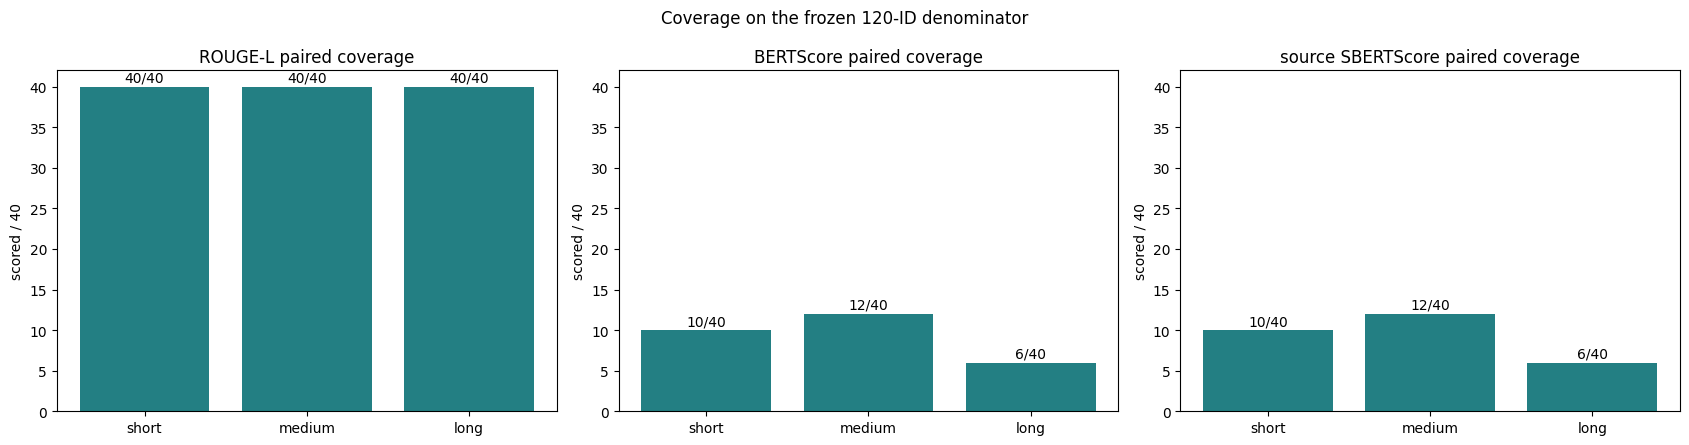

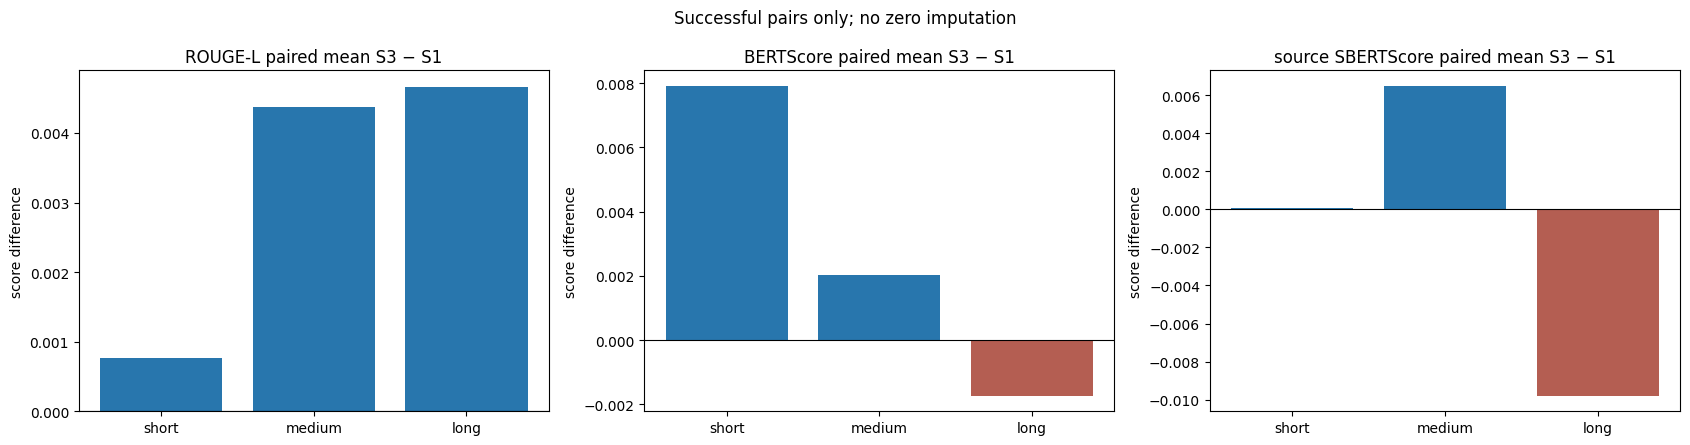

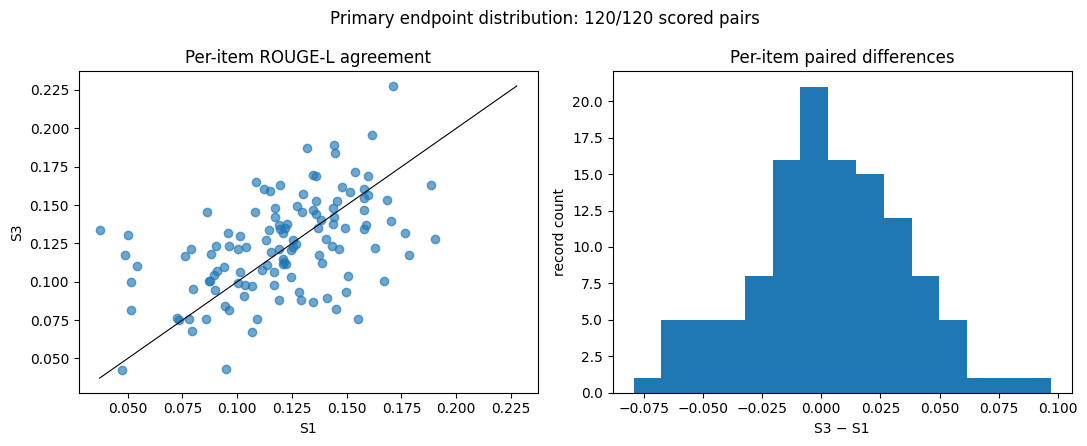

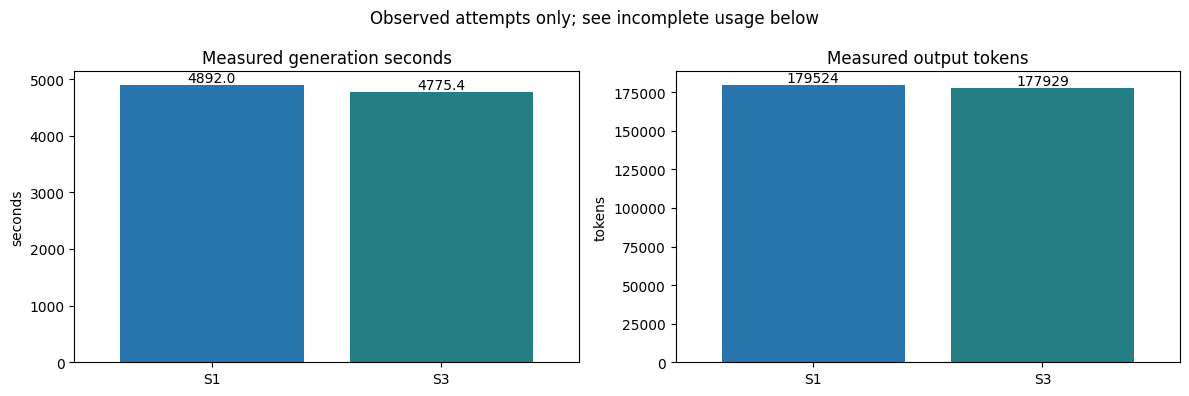

Saved figures: /content/drive/MyDrive/RQ2_TIB_120_20261012/formal-run-v1/paired-coverage.png /content/drive/MyDrive/RQ2_TIB_120_20261012/formal-run-v1/paired-stratum-deltas.png /content/drive/MyDrive/RQ2_TIB_120_20261012/formal-run-v1/primary-paired-distribution.png /content/drive/MyDrive/RQ2_TIB_120_20261012/formal-run-v1/measured-arm-resources.png


,attempts,prompt_tokens,output_tokens,generation_seconds,segmentation_seconds,usage_incomplete_attempts
S1,120.0,894704.0,179524.0,4892.003137,455.855550,0.0
S3,120.0,899830.0,177929.0,4775.379347,435.636479,0.0


Unknown usage: {'dispatches': 1850, 'known_input_tokens': 1794534, 'known_output_tokens': 357453, 'unknown_output_dispatches': 0, 'possibly_attempted_records_with_unknown_input_and_output_usage': 0, 'total_output_tokens': 357453}
Failure and unattempted IDs:


,id,stratum,status,S1_status,S3_status,error,evaluation_error
0,valid/208,short,evaluation_failed,completed,completed,None,ValueError: Retokenized sentence window exceed...
1,valid/210,medium,generated,completed,completed,None,None
2,valid/215,long,generated,completed,completed,None,None
3,valid/244,short,generated,completed,completed,None,None
4,valid/246,medium,generated,completed,completed,None,None
...,...,...,...,...,...,...,...
87,valid/850,long,generated,completed,completed,None,None
88,valid/853,long,generated,completed,completed,None,None
89,valid/854,long,generated,completed,completed,None,None
90,valid/862,medium,generated,completed,completed,None,None


In [11]:
import matplotlib.pyplot as plt

order=['short','medium','long']
metric_reports={'ROUGE-L':'rouge_l','BERTScore':'bertscore',
                'source SBERTScore':'sbertscore'}
fig,axes=plt.subplots(1,3,figsize=(17,4.5))
for ax,(label,key) in zip(axes,metric_reports.items()):
    report=summary['metrics'][key]
    counts=[report['strata'][s]['paired_scored'] for s in order]
    ax.bar(order,counts,color='#237f83')
    ax.set(title=label+' paired coverage',ylabel='scored / 40',ylim=(0,42))
    for i,count in enumerate(counts): ax.text(i,count+0.6,f'{count}/40',ha='center')
fig.suptitle('Coverage on the frozen 120-ID denominator')
fig.tight_layout(); fig.savefig(RUN/'paired-coverage.png',dpi=150,bbox_inches='tight'); plt.show()

fig,axes=plt.subplots(1,3,figsize=(17,4.5))
for ax,(label,key) in zip(axes,metric_reports.items()):
    report=summary['metrics'][key]
    valid=[(s,report['strata'][s]['S3_minus_S1']) for s in order
           if report['strata'][s]['S3_minus_S1'] is not None]
    if valid:
        ax.bar([s for s,_ in valid],[v for _,v in valid],
            color=['#2876ad' if v>=0 else '#b45e52' for _,v in valid])
    ax.axhline(0,color='black',linewidth=.8)
    ax.set(title=label+' paired mean S3 − S1',ylabel='score difference')
    if not valid: ax.text(.5,.5,'No paired scores',transform=ax.transAxes,ha='center')
fig.suptitle('Successful pairs only; no zero imputation')
fig.tight_layout(); fig.savefig(RUN/'paired-stratum-deltas.png',dpi=150,bbox_inches='tight'); plt.show()

paired=results.dropna(subset=['ROUGE-L_S1','ROUGE-L_S3'])
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
if len(paired):
    axes[0].scatter(paired['ROUGE-L_S1'],paired['ROUGE-L_S3'],alpha=.65)
    lower=min(paired[['ROUGE-L_S1','ROUGE-L_S3']].min())
    upper=max(paired[['ROUGE-L_S1','ROUGE-L_S3']].max())
    axes[0].plot([lower,upper],[lower,upper],color='black',linewidth=.8)
    axes[1].hist(paired['ROUGE-L_S3_minus_S1'],bins=min(15,max(1,len(paired))))
else:
    for ax in axes: ax.text(.5,.5,'No paired scores',transform=ax.transAxes,ha='center')
axes[0].set(title='Per-item ROUGE-L agreement',xlabel='S1',ylabel='S3')
axes[1].set(title='Per-item paired differences',xlabel='S3 − S1',ylabel='record count')
fig.suptitle(f'Primary endpoint distribution: {len(paired)}/120 scored pairs')
fig.tight_layout(); fig.savefig(RUN/'primary-paired-distribution.png',dpi=150,bbox_inches='tight'); plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,field,unit in ((axes[0],'generation_seconds','seconds'),
                      (axes[1],'output_tokens','tokens')):
    values=[summary['resources_by_arm'][arm][field] for arm in ('S1','S3')]
    for i,value in enumerate(values):
        if value is not None: ax.bar(i,value,color=['#2876ad','#237f83'][i])
    ax.set_xticks((0,1),('S1','S3'))
    ax.set_xlim(-.6,1.6)
    ax.set(title='Measured '+field.replace('_',' '),ylabel=unit)
    for i,value in enumerate(values):
        ax.text(i,0 if value is None else value,
            str(round(value,1)) if value is not None else 'unavailable',ha='center',va='bottom')
fig.suptitle('Observed attempts only; see incomplete usage below')
fig.tight_layout(); fig.savefig(RUN/'measured-arm-resources.png',dpi=150,bbox_inches='tight'); plt.show()
print('Saved figures:',*(RUN/name for name in ('paired-coverage.png',
    'paired-stratum-deltas.png','primary-paired-distribution.png','measured-arm-resources.png')))
display(pd.DataFrame(summary['resources_by_arm']).T)
print('Unknown usage:',summary['dispatch_usage'])
print('Failure and unattempted IDs:')
display(results.loc[(results['status']!='completed') | results['error'].notna() |
    results['evaluation_error'].notna(),['id','stratum','status','S1_status','S3_status',
    'error','evaluation_error']].reset_index(drop=True))
